# Scalar-induced gravitational waves for a general equation of state

Updated implementation notes:

- The scalar transfer function is stored as the Newtonian potential per unit curvature perturbation, so the primordial spectrum functions below should return `P_zeta(k)`.
- `Phi_mat_*` and `Phi_prime_mat_*` are saved in separate chunks. `Phi_prime` is the conformal-time derivative `dPhi/deta`, matching the source term.
- The tensor Green function is built for the variable `g = a h`, following the form used in arXiv:2307.01653.
- Heavy precomputation cells are guarded by flags. Set them to `True` only when you want to regenerate the transfer/function or kernel cache.


In [26]:
# for latex rendering


import matplotlib as mpl
import matplotlib.pyplot as plt
plt.rcParams['savefig.dpi'] = 75
mpl.rcParams.update({'font.size': 22, 'font.family': 'serif'})
plt.rcParams['figure.autolayout'] = False
plt.rcParams['figure.figsize'] = 10, 6 #6.4, 4.8
plt.rcParams['axes.labelsize'] = 18
plt.rcParams['axes.titlesize'] = 20
plt.rcParams['font.size'] = 16
plt.rcParams['lines.linewidth'] = 2.0
plt.rcParams['lines.markersize'] = 8
plt.rcParams['legend.fontsize'] = 15
mpl.rc('axes',edgecolor='k')
plt.rcParams['xtick.color'] = 'k'
plt.rcParams['ytick.color'] = 'k'
plt.rcParams["axes.axisbelow"] = False
plt.rcParams["xtick.major.size"] = 6
plt.rcParams["xtick.minor.size"] = 3
plt.rcParams["ytick.major.size"] = 6
plt.rcParams["ytick.minor.size"] = 3
plt.rcParams['xtick.direction'] = 'in'
plt.rcParams['ytick.direction'] = 'in'
plt.rcParams['text.usetex'] = True 
colors = plt.get_cmap('tab10')


In [27]:
from pathlib import Path
from dataclasses import dataclass
from concurrent.futures import ThreadPoolExecutor
import json
import math
import warnings

import numpy as np
from scipy.integrate import simpson, solve_ivp, trapezoid
from scipy.optimize import minimize_scalar
from scipy.interpolate import CubicHermiteSpline, CubicSpline, RectBivariateSpline, RegularGridInterpolator
from numpy.polynomial.legendre import leggauss
import matplotlib.pyplot as plt

# Resolve this notebook's model tables, including when launched from project root.
import hashlib
PROJECT_CANDIDATES = [
    Path.cwd(), Path.cwd() / 'sigw' / 'SIGW_EOS' / 'SIGW_EOS',
    Path.cwd() / 'SIGW_EOS' / 'SIGW_EOS', Path.cwd() / 'SIGW_EOS',
    Path.cwd().parent,
]
PROJECT_DIR = next((p.resolve() for p in PROJECT_CANDIDATES
                    if (p / 'transferfunction').exists()
                    and (p / 'SIGW_EoS_BSM.ipynb').exists()), None)
if PROJECT_DIR is None:
    raise FileNotFoundError('Start Jupyter in this project or set PROJECT_DIR to the model notebook directory.')
TRANSFER_DIR = PROJECT_DIR / 'transferfunction'
DATA_DIR = PROJECT_DIR / 'data'
# Isolate all production caches from the old T=C/eta background.
# Changes to tables, thermal code, background settings, Phi or Green definitions
# select a new directory; unchanged inputs reuse it. Existing files are preserved.
# Cache version for the local high-T thermal and BSM definitions.
_digest = hashlib.sha256(b'bsm-inline-background-v1')
for _name in ('omega2_new_merged.csv', 'cs2_new_merged.csv'):
    _digest.update((TRANSFER_DIR / _name).read_bytes())
BSM_MODE_CONFIGS = {
    'Nc5': {'N_c': 5, 'r_g': ((45.0 / 4.0) * 5.0**2 - 4.0) / 106.75},
    'Nc10': {'N_c': 10, 'r_g': ((45.0 / 4.0) * 10.0**2 - 4.0) / 106.75},
}
BSM_MODE = 'Nc5'  # switch to 'Nc10' and rerun from the background cell
if BSM_MODE not in BSM_MODE_CONFIGS:
    raise ValueError(f'Unknown BSM_MODE={BSM_MODE!r}; choose {tuple(BSM_MODE_CONFIGS)}')
_digest.update(BSM_MODE.encode('ascii'))
BACKGROUND_FINGERPRINT = _digest.hexdigest()
CACHE_CASE = f'QCD_adiabatic_composite_{BSM_MODE.lower()}_highT'
TENSOR_INCLUDE_W_CORRECTION = True
CACHE_DIR = DATA_DIR / CACHE_CASE
PHI_CACHE_DIR = CACHE_DIR / 'phi'
GREEN_CACHE_DIR = CACHE_DIR / 'green'
KERNEL_CACHE_DIR = CACHE_DIR / 'kernel'
for directory in (DATA_DIR, CACHE_DIR, PHI_CACHE_DIR, GREEN_CACHE_DIR, KERNEL_CACHE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print('PROJECT_DIR =', PROJECT_DIR)
print('TRANSFER_DIR =', TRANSFER_DIR)


PROJECT_DIR = C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS
TRANSFER_DIR = C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS\transferfunction


In [28]:
# Thermal background equations used by this notebook.


MEV_TO_MPC_INV = 5.067730716e12 * 3.085677581491367e22


def load_thermal_eos(w_path, cs2_path, temperature_constant):
    """Recover w(T), cs2(T) from matching legacy C/T tables."""
    tables = [np.loadtxt(p, delimiter=',') for p in (w_path, cs2_path)]
    for table in tables:
        if table.ndim != 2 or table.shape[1] != 2 or not np.all(np.isfinite(table)):
            raise ValueError('EoS tables require two finite numeric columns.')
        table[:] = table[np.argsort(table[:, 0])]
        if np.any(table[:, 0] <= 0) or np.any(np.diff(table[:, 0]) <= 0):
            raise ValueError('Legacy coordinates must be positive and distinct.')
    w, cs2 = tables
    if w.shape != cs2.shape or not np.allclose(w[:, 0], cs2[:, 0], rtol=1e-12, atol=0):
        raise ValueError('w and cs2 must have the same legacy coordinate grid.')
    if temperature_constant <= 0 or np.any(cs2[:, 1] <= 0):
        raise ValueError('Require positive C and cs2 for thermal evolution.')
    temperature = temperature_constant / w[::-1, 0]
    return dict(w_table=w, cs2_table=cs2, temperature=temperature,
                log_temperature=np.log(temperature),
                w=CubicSpline(np.log(temperature), w[::-1, 1]),
                cs2=CubicSpline(np.log(temperature), cs2[::-1, 1]))


def thermal_eos_value(eos, temperature, key, derivative=False):
    """Evaluate a table or d/dlnT; use radiation outside its temperature range."""
    temperature = np.asarray(temperature, dtype=float)
    if np.any(~np.isfinite(temperature)) or np.any(temperature <= 0):
        raise ValueError('Temperature must be finite and positive.')
    lo, hi = eos['log_temperature'][[0, -1]]
    log_t = np.log(temperature)
    inside = (log_t >= lo) & (log_t <= hi)
    value = eos[key](np.clip(log_t, lo, hi), 1 if derivative else 0)
    out = np.where(inside, value, 0.0 if derivative else 1.0 / 3.0)
    return float(out) if out.ndim == 0 else out


def background_values(background, eta):
    """Return (a, calH, T), with radiation extensions continuous in a, a', H, T.

    Beyond either endpoint use a shifted radiation conformal time, i.e.
    H=H_b/[1+H_b*(eta-eta_b)], a=a_b*[1+H_b*(eta-eta_b)].
    The early endpoint has q=1; this reduces to the usual early RD scaling.
    """
    eta = np.asarray(eta, dtype=float)
    if np.any(~np.isfinite(eta)) or np.any(eta <= 0):
        raise ValueError('Conformal time must be finite and positive.')
    clipped = np.clip(eta, background['eta_min'], background['eta_max'])
    log_eta = np.log(clipped)
    a = np.exp(background['log_a_spline'](log_eta))
    h = background['q_spline'](log_eta) / clipped
    temperature = np.exp(background['log_temperature_spline'](log_eta))
    scale = 1.0 + h * (eta - clipped)
    # Avoid subtraction cancellation far below eta_min, where q is exactly 1.
    scale = np.where(eta < background['eta_min'], eta / clipped, scale)
    return a * scale, h / scale, temperature / scale


def solve_thermal_background_from_highT(
    w_temperature, cs2_temperature, *, T_high, g_rho_high, g_s_high,
    T0_physical, g_s0=3.94, Mpl_MeV=2.4353e21,
    eta_max=1e1, n_points=14001,
    rtol=1e-10, atol=1e-12, max_step=0.05,
):
    """Integrate the thermal history downward from a high-T radiation boundary.

    ``T_high`` is chosen above the first phase transition.  At that point we
    impose radiation domination, q=eta*calH=1, and use entropy conservation
    to set the scale factor.  The physical Hubble rate fixes the absolute
    conformal-time boundary,

        eta_high = 1 / (a_phys(T_high) H_phys(T_high)).

    Below ``eta_high`` :func:`background_values` supplies the analytic
    radiation extension.  This fixes the conformal-time zero at the assumed
    initial singularity rather than at an arbitrary finite temperature.
    """
    if not (T_high > 0 and g_rho_high > 0 and g_s_high > 0
            and T0_physical > 0 and Mpl_MeV > 0):
        raise ValueError('High-T boundary parameters must be positive.')
    if eta_max <= 0 or int(n_points) < 3:
        raise ValueError('Invalid eta upper limit or grid size.')

    # a_phys is normalized to unity today.  No late-time renormalization is
    # applied: doing so would break the physical Friedmann calibration.
    a_phys_high = (T0_physical / T_high) * (g_s0 / g_s_high) ** (1.0 / 3.0)
    H_high_MeV = np.sqrt(np.pi**2 * g_rho_high / 90.0) * T_high**2 / Mpl_MeV
    H_high_Mpc = H_high_MeV * MEV_TO_MPC_INV
    eta_high = 1.0 / (a_phys_high * H_high_Mpc)
    if not eta_high < eta_max:
        raise ValueError(
            f'T_high={T_high:g} MeV is too low: eta_high={eta_high:g} '
            f'must be below eta_max={eta_max:g}.'
        )

    log_eta = np.linspace(np.log(eta_high), np.log(eta_max), int(n_points))

    def rhs(log_eta_value, state):
        temperature = np.exp(state[2])
        w = float(np.asarray(w_temperature(temperature)))
        cs2 = float(np.asarray(cs2_temperature(temperature)))
        q = state[1]
        return [q, q - 0.5 * (1.0 + 3.0 * w) * q**2, -3.0 * cs2 * q]

    solution = solve_ivp(
        rhs, (log_eta[0], log_eta[-1]),
        (np.log(a_phys_high), 1.0, np.log(T_high)),
        t_eval=log_eta, method='DOP853', rtol=rtol, atol=atol,
        max_step=max_step,
    )
    if not solution.success:
        raise RuntimeError(f'High-T thermal background failed: {solution.message}')

    log_a = solution.y[0]
    eta = np.exp(log_eta)
    return dict(
        eta=eta, log_eta=log_eta, a=np.exp(log_a),
        conH=solution.y[1] / eta, temperature=np.exp(solution.y[2]),
        eta_min=float(eta_high), eta_max=float(eta_max),
        high_temperature=float(T_high),
        high_g_rho=float(g_rho_high), high_g_s=float(g_s_high),
        high_eta=float(eta_high), high_a_phys=float(a_phys_high),
        high_H_Mpc=float(H_high_Mpc),
        log_a_spline=CubicSpline(log_eta, log_a),
        q_spline=CubicSpline(log_eta, solution.y[1]),
        log_temperature_spline=CubicSpline(log_eta, solution.y[2]),
    )


def solve_eta_control_background(eta_grid, w_eta, cs2_eta, a_norm,
                                 eta_norm=1e-2, rtol=1e-10, atol=1e-12,
                                 max_step=0.05):
    """Solve a control background using coefficient curves tabulated in eta.

    ``w_eta`` and ``cs2_eta`` are evaluated on the *reference eta grid* and
    are not re-sampled through a temperature evolution.  This is intended
    for the notebook's manual controls, where e.g. ``cs2=1/3`` keeps the
    full-model ``w(eta)`` curve at the same eta values.
    """
    eta_grid = np.asarray(eta_grid, dtype=float)
    w_eta = np.asarray(w_eta, dtype=float)
    cs2_eta = np.asarray(cs2_eta, dtype=float)
    if (eta_grid.ndim != 1 or len(eta_grid) < 3
            or np.any(~np.isfinite(eta_grid)) or np.any(eta_grid <= 0)
            or np.any(np.diff(eta_grid) <= 0)):
        raise ValueError('eta_grid must be finite, positive and increasing.')
    if w_eta.shape != eta_grid.shape or cs2_eta.shape != eta_grid.shape:
        raise ValueError('w_eta and cs2_eta must match eta_grid.')
    if not (eta_grid[0] < eta_norm < eta_grid[-1]) or a_norm <= 0:
        raise ValueError('Invalid eta normalization or grid.')
    log_eta = np.log(eta_grid)
    w_spline = CubicSpline(log_eta, w_eta)
    cs2_spline = CubicSpline(log_eta, cs2_eta)

    def rhs(log_eta_value, state):
        w = float(w_spline(log_eta_value))
        q = state[1]
        return [q, q - 0.5 * (1.0 + 3.0 * w) * q**2,
                -3.0 * float(cs2_spline(log_eta_value)) * q]

    sol = solve_ivp(rhs, (log_eta[0], log_eta[-1]),
                    (0.0, 1.0, 0.0), t_eval=log_eta, method='DOP853',
                    rtol=rtol, atol=atol, max_step=max_step)
    if not sol.success:
        raise RuntimeError(f'Eta-control background failed: {sol.message}')
    log_a = sol.y[0] + np.log(a_norm) - CubicSpline(log_eta, sol.y[0])(
        np.log(eta_norm))
    eta = eta_grid
    return dict(eta=eta, log_eta=log_eta, a=np.exp(log_a),
                conH=sol.y[1] / eta, temperature=np.exp(sol.y[2]),
                eta_min=float(eta[0]), eta_max=float(eta[-1]),
                log_a_spline=CubicSpline(log_eta, log_a),
                q_spline=CubicSpline(log_eta, sol.y[1]),
                log_temperature_spline=CubicSpline(log_eta, sol.y[2]),
                w_spline=w_spline, cs2_spline=cs2_spline)


## Self-consistent QCD + Composite-Higgs thermal background

The low-temperature branch uses the merged QCD `omega2_new_merged.csv` and `cs2_new_merged.csv` tables. Above the upper QCD temperature, the analytic Composite-Higgs branch is used. The notebook solves the coupled FLRW and temperature equations to obtain a single consistent $T(\eta)$ relation for both branches.


In [29]:
from scipy.special import kv
from scipy.integrate import solve_ivp
from scipy.interpolate import CubicSpline

RADIATION_W = 1.0 / 3.0
OMEGA_R0_H2 = 4.2e-5
SPEED_OF_LIGHT_M_S = 299_792_458.0
MPC_METERS = 3.085677581491367e22
K_MPC_TO_HZ = SPEED_OF_LIGHT_M_S / (2.0 * np.pi * MPC_METERS)

def k_mpc_to_hz(k_mpc):
    return np.asarray(k_mpc, dtype=float) * K_MPC_TO_HZ

def hz_to_k_mpc(f_hz):
    return np.asarray(f_hz, dtype=float) / K_MPC_TO_HZ

eta0 = 1.0
h = 675 / 1000
Omega_r = 247e-7 / h**2
Omega_v = 3 * 7 / 8 * (4 / 11)**(4 / 3) * Omega_r
a0 = h / (3e+3) * (Omega_r + Omega_v)**0.5 * eta0
T0 = 2.73 * 8.6e-11 / a0 * (3.94 / 10)**(1 / 3)
Mpl = 2.4353e21
DIRECT_ETA_T_CONSTANT = T0 * eta0

BSM_PARAMS = BSM_MODE_CONFIGS[BSM_MODE]
BSM_NC = float(BSM_PARAMS['N_c'])
BSM_RG = float(BSM_PARAMS['r_g'])
BSM_TC_MEV = 1.0e7
BSM_MASS_MEV = BSM_TC_MEV

# The new merged QCD tables are the low-temperature branch. The analytic
# Composite-Higgs branch takes over above their upper temperature endpoint.
THERMAL_EOS_QCD = load_thermal_eos(
    TRANSFER_DIR / 'omega2_new_merged.csv',
    TRANSFER_DIR / 'cs2_new_merged.csv',
    DIRECT_ETA_T_CONSTANT,
)
QCD_T_MIN, QCD_T_MAX = np.exp(THERMAL_EOS_QCD['log_temperature'][[0, -1]])


def composite_eos_temperature(temperature, r_g=BSM_RG, mass=BSM_MASS_MEV):
    temperature = np.asarray(temperature, dtype=float)
    x = np.maximum(mass / temperature, 1e-8)
    p = x*x*kv(2, x)/2
    rho = p + x**3*kv(1, x)/6
    dp = -x*x*kv(1, x)/2
    drho = -x*x*kv(1, x)/6 - x**3*kv(0, x)/6
    w = (1 + r_g*p) / (3 * (1 + r_g*rho))
    cs2 = (4*(1 + r_g*p) - r_g*x*dp) / (3*(4*(1 + r_g*rho) - r_g*x*drho))
    return w, cs2


def eos_temperature(temperature):
    temperature = np.asarray(temperature, dtype=float)
    qcd_w = thermal_eos_value(THERMAL_EOS_QCD, temperature, 'w')
    composite_w = composite_eos_temperature(temperature)[0]
    out = np.where(temperature <= QCD_T_MAX, qcd_w, composite_w)
    return float(out) if out.ndim == 0 else out


def cs2_temperature(temperature):
    temperature = np.asarray(temperature, dtype=float)
    qcd_cs2 = thermal_eos_value(THERMAL_EOS_QCD, temperature, 'cs2')
    composite_cs2 = composite_eos_temperature(temperature)[1]
    out = np.where(temperature <= QCD_T_MAX, qcd_cs2, composite_cs2)
    return float(out) if out.ndim == 0 else out


def eos(eta):
    return eos_temperature(temperature_interp(eta))


def c_s_sq(eta):
    return cs2_temperature(temperature_interp(eta))


def cs2_prime(eta):
    eta = np.asarray(eta, dtype=float)
    temperature = temperature_interp(eta)
    # Numerical derivative in ln T is stable for both table and analytic branches.
    step = 1e-4
    derivative = (cs2_temperature(temperature * np.exp(step))
                  - cs2_temperature(temperature * np.exp(-step))) / (2 * step)
    return derivative * (-3 * conH_interp(eta) * cs2_temperature(temperature))


# Draft composite-Higgs UV degrees of freedom:
# g_elem=106.75-4, g_comp=(45/4)*N_c^2.
T0_PHYSICAL_MEV = 2.73 * 8.6e-11
BSM_HIGH_G = 102.75 + (45.0 / 4.0) * BSM_NC**2
BSM_HIGH_T_MEV = 1.0e3 * BSM_TC_MEV
BACKGROUND_SETTINGS = dict(
    T_high=BSM_HIGH_T_MEV, g_rho_high=BSM_HIGH_G, g_s_high=BSM_HIGH_G,
    T0_physical=T0_PHYSICAL_MEV, g_s0=3.94, Mpl_MeV=Mpl,
    eta_max=1e1, n_points=18001,
    rtol=1e-10, atol=1e-12, max_step=0.03,
)
background = solve_thermal_background_from_highT(
    eos_temperature, cs2_temperature, **BACKGROUND_SETTINGS)


def _background_values(eta):
    return background_values(background, eta)[:2]


def temperature_interp(eta):
    return background_values(background, eta)[2]


def a_interp(eta):
    return _background_values(eta)[0]


def conH_interp(eta):
    return _background_values(eta)[1]


def aprime_interp(eta):
    return a_interp(eta) * conH_interp(eta)


def a_doubleprime_over_a(eta):
    return 0.5 * (1 - 3 * eos(eta)) * conH_interp(eta)**2


def a_doubleprime_interp(eta):
    return a_interp(eta) * a_doubleprime_over_a(eta)


def conHprime(eta):
    return -0.5 * (1 + 3 * eos(eta)) * conH_interp(eta)**2


def conHprime_interp(eta):
    return conHprime(eta)

H_min_eta, H_max_eta = background['eta_min'], background['eta_max']
a_min_eta, a_max_eta = H_min_eta, H_max_eta
# QCD table interval in physical eta, obtained from the solved T(eta).
_qcd_mask = (background['temperature'] >= QCD_T_MIN) & (background['temperature'] <= QCD_T_MAX)
w_min_eta, w_max_eta = background['eta'][_qcd_mask][[0, -1]]
cs_min_eta, cs_max_eta = w_min_eta, w_max_eta
BSM_ETA_TC = float(np.interp(BSM_TC_MEV, background['temperature'][::-1], background['eta'][::-1]))
(CACHE_DIR / 'background_metadata.json').write_text(json.dumps(dict(
    fingerprint=BACKGROUND_FINGERPRINT, settings=BACKGROUND_SETTINGS,
    temperature_constant_MeV_Mpc=DIRECT_ETA_T_CONSTANT,
    QCD_temperature_range_MeV=(float(QCD_T_MIN), float(QCD_T_MAX)),
    composite_higgs_mass_MeV=float(BSM_MASS_MEV),
    composite_higgs_transition_temperature_MeV=float(BSM_TC_MEV),
    composite_higgs_eta=float(BSM_ETA_TC),
    table_coordinate='C/T; high-temperature radiation boundary and thermal T(eta)',
    eta_boundary_Mpc=background['high_eta'],
    a_phys_boundary=background['high_a_phys'],
    H_boundary_Mpc_inv=background['high_H_Mpc'],
    calibration='physical a(T_high), H(T_high), eta=1/(aH); a_today=1',
), indent=2))
print('QCD input T range:', QCD_T_MIN, QCD_T_MAX)
print('Composite Higgs mass/Tc [MeV]:', BSM_MASS_MEV, BSM_TC_MEV)
print('Composite Higgs eta(Tc):', BSM_ETA_TC)
print('background eta range:', H_min_eta, H_max_eta)
print('background T range:', background['temperature'][0], background['temperature'][-1])


def tensor_mass_over_k2(eta, k, include_w_correction=None):
    h_over_k = conH_interp(eta) / k
    if include_w_correction is None:
        include_w_correction = TENSOR_INCLUDE_W_CORRECTION
    if not include_w_correction:
        return np.zeros_like(h_over_k, dtype=float)
    return 0.5 * (1.0 - 3.0 * eos(eta)) * h_over_k**2


def today_redshift_factor(eta_c, eta_f=None, omega_r0_h2=OMEGA_R0_H2):
    if eta_f is None:
        eta_f = H_max_eta
    numerator = a_interp(eta_c) * conH_interp(eta_c)
    denominator = a_interp(eta_f) * conH_interp(eta_f)
    return omega_r0_h2 * (numerator / denominator)**2


QCD input T range: 0.010000000000000004 999999.9999999995
Composite Higgs mass/Tc [MeV]: 10000000.0 10000000.0
Composite Higgs eta(Tc): 4.796740180944136e-12
background eta range: 4.704116472761227e-15 10.0
background T range: 10000000000.000004 9.043954748715642e-06


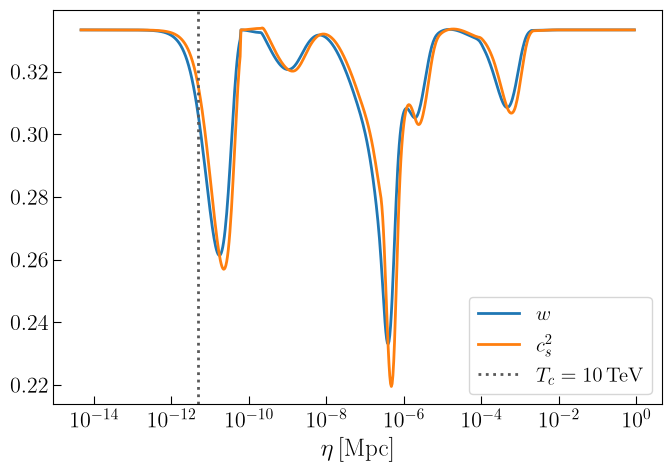

In [30]:
# Quick background sanity plot. The BSM branch is at smaller eta than the
# native SM tables, so include the full solved history in the diagnostic.
eta_plot = np.geomspace(background['eta_min'], max(cs_max_eta, w_max_eta)*100, 700)
w_plot = eos(eta_plot)
cs2_plot = c_s_sq(eta_plot)
plt.figure(figsize=(7, 5))
plt.plot(eta_plot, w_plot, label=r'$w$')
plt.plot(eta_plot, cs2_plot, label=r'$c_s^2$')
plt.axvline(BSM_ETA_TC, color='0.35', ls=':', label=r'$T_c=10\,\mathrm{TeV}$')
plt.xscale('log')
plt.xlabel(r'$\eta\,[\mathrm{Mpc}]$')
plt.legend()
plt.tight_layout()
if '__file__' not in globals():
    plt.show()
else:
    plt.close()


## Scalar transfer function `Phi`

The Bardeen equation is implemented in the form used in arXiv:2307.01653,

\[
\Phi_k''+3\mathcal{H}(1+c_s^2)\Phi_k'
+\left[c_s^2 k^2+3\mathcal{H}^2(c_s^2-w)\right]\Phi_k=0.
\]

The ODE is solved in the dimensionless variable `x = k eta`, which is faster and numerically better scaled. At `x_ini`, the decaying mode is removed and the growing superhorizon solution $\Phi=-A(\eta)$ is used, with $A=1-\mathcal{H}a^{-2}\int_0^\eta a^2d\tilde\eta$. The saved `Phi_prime_mat_*` remains `dPhi/deta`.


In [31]:
X_INI = 1e-3
X_FINAL = 1e3
N_X_DEFAULT = 8000
PHI_RTOL = 3e-8
PHI_ATOL = 1e-10
PHI_INITIAL_CONDITION = 'analytic_superhorizon_v1' # initial condition: 'analytic_superhorizon_v1' or 'pure_radiation'

@dataclass(frozen=True)
class TransferChunk:
    label: str
    k_min: float
    k_max: float
    n_k: int


PHI_CHUNKS = [
    # Extend to 1e-2--1e16 Mpc^-1 without changing existing chunk grids.
    TransferChunk('02', 1e0, 1e2, 120),
    TransferChunk('24', 1e2, 1e4, 200),
    TransferChunk('46', 1e4, 1e6, 200),
    TransferChunk('68', 1e6, 1e8, 200),
    TransferChunk('810', 1e8, 1e10, 200),
    TransferChunk('1014', 1e10, 1e14, 400),
    TransferChunk('1416', 1e14, 1e16, 400),
]


def phi_rhs_x(x, y, k):
    phi, dphi_dx = y
    eta = x / k
    h_over_k = conH_interp(eta) / k
    cs2 = c_s_sq(eta)
    w = eos(eta)
    d2phi_dx2 = -3.0 * (1.0 + cs2) * h_over_k * dphi_dx - (cs2 + 3.0 * h_over_k**2 * (cs2 - w)) * phi
    return [dphi_dx, d2phi_dx2]


_SUPERHORIZON_ETA_GRID = background['eta']
_SUPERHORIZON_A2 = background['a']**2
_SUPERHORIZON_EARLY_CUM = _SUPERHORIZON_A2[0] * _SUPERHORIZON_ETA_GRID[0] / 3.0
_SUPERHORIZON_CUM = _SUPERHORIZON_EARLY_CUM + np.concatenate(([0.0], np.cumsum(0.5 * (_SUPERHORIZON_A2[1:] + _SUPERHORIZON_A2[:-1]) * np.diff(_SUPERHORIZON_ETA_GRID))))

def _superhorizon_integral(eta, n_points=4096):
    """Integral from eta=0 through the complete SM+BSM history."""
    eta = np.asarray(eta, dtype=float)
    clipped = np.clip(eta, _SUPERHORIZON_ETA_GRID[0], _SUPERHORIZON_ETA_GRID[-1])
    value = np.interp(clipped, _SUPERHORIZON_ETA_GRID, _SUPERHORIZON_CUM)
    value = value + np.where(eta < _SUPERHORIZON_ETA_GRID[0], _SUPERHORIZON_A2[0] * _SUPERHORIZON_ETA_GRID[0] / 3.0 * (eta / _SUPERHORIZON_ETA_GRID[0])**3 - _SUPERHORIZON_EARLY_CUM, 0.0)
    return float(value) if value.ndim == 0 else value


def superhorizon_mode(eta):
    """Growing adiabatic superhorizon mode A(eta), with decay mode removed."""
    eta = float(eta)
    integral = _superhorizon_integral(eta)
    return 1.0 - conH_interp(eta) * integral / a_interp(eta)**2


def superhorizon_mode_prime(eta):
    """Conformal-time derivative of the growing superhorizon mode."""
    eta = float(eta)
    if eta < background['eta_min']:
        return 0.0
    integral_over_a2 = _superhorizon_integral(eta) / a_interp(eta)**2
    H = conH_interp(eta)
    return -(conHprime_interp(eta) - 2.0 * H**2) * integral_over_a2 - H


def solve_phi_transfer(
    k,
    x_grid=None,
    rtol=PHI_RTOL,
    atol=PHI_ATOL,
    initial_condition=PHI_INITIAL_CONDITION,
):
    if x_grid is None:
        x_grid = np.geomspace(X_INI, X_FINAL, N_X_DEFAULT)
    k = float(k)
    x0 = float(x_grid[0])
    eta0 = x0 / k
    if initial_condition == 'analytic_superhorizon_v1':
        # Growing superhorizon solution per unit zeta, as in SIGW_EoS.ipynb:
        # Phi=-A(eta), dPhi/dx=-A'(eta)/k; the decaying mode is set to zero.
        y0 = [-superhorizon_mode(eta0), -superhorizon_mode_prime(eta0) / k]
    elif initial_condition == 'pure_radiation':
        # Radiation-era analytic solution at x_ini=k*eta_ini.
        y0 = [-2.0 / 3.0 * (1.0 - x0**2 / 30.0), 2.0 * x0 / 45.0]
    else:
        raise ValueError(
            f"initial_condition must be {PHI_INITIAL_CONDITION!r} or 'pure_radiation'"
        )
    sol = solve_ivp(
        phi_rhs_x,
        (float(x_grid[0]), float(x_grid[-1])),
        y0,
        t_eval=x_grid,
        args=(k,),
        method='DOP853',
        rtol=rtol,
        atol=atol,
    )
    if not sol.success:
        raise RuntimeError(f'Phi solver failed for k={k:.6g}: {sol.message}')
    phi = sol.y[0]
    phi_prime_eta = k * sol.y[1]
    return phi, phi_prime_eta


def _chunk_paths(chunk, directory=PHI_CACHE_DIR):
    return {
        'phi': directory / f'Phi_mat_{chunk.label}.npy',
        'phi_prime': directory / f'Phi_prime_mat_{chunk.label}.npy',
        'meta': directory / f'Phi_meta_{chunk.label}.json',
    }


def _phi_cache_compatible(chunk, directory=PHI_CACHE_DIR, n_x=N_X_DEFAULT):
    paths = _chunk_paths(chunk, directory=directory)
    if not (paths['phi'].exists() and paths['phi_prime'].exists() and paths['meta'].exists()):
        return False
    try:
        meta = json.loads(paths['meta'].read_text())
    except (OSError, json.JSONDecodeError):
        return False
    return (
        meta.get('label') == chunk.label
        and np.isclose(float(meta.get('k_min')), chunk.k_min)
        and np.isclose(float(meta.get('k_max')), chunk.k_max)
        and int(meta.get('n_k')) == int(chunk.n_k)
        and np.isclose(float(meta.get('x_ini')), X_INI)
        and np.isclose(float(meta.get('x_final')), X_FINAL)
        and int(meta.get('n_x')) == int(n_x)
        and meta.get('initial_condition') == PHI_INITIAL_CONDITION
    )


def save_phi_chunk(chunk, n_x=N_X_DEFAULT, overwrite=False):
    paths = _chunk_paths(chunk)
    cache_exists = paths['phi'].exists() and paths['phi_prime'].exists()
    if not overwrite and cache_exists and _phi_cache_compatible(chunk, n_x=n_x):
        print(f'Phi chunk {chunk.label} already exists with initial_condition={PHI_INITIAL_CONDITION}; reusing it')
        return
    if cache_exists and not _phi_cache_compatible(chunk, n_x=n_x):
        print(f'Phi chunk {chunk.label} has incompatible metadata; regenerating it')
    x_grid = np.geomspace(X_INI, X_FINAL, int(n_x))
    k_grid = np.geomspace(chunk.k_min, chunk.k_max, chunk.n_k)
    phi_mat = np.empty((chunk.n_k, int(n_x)), dtype=np.float64)
    phi_prime_mat = np.empty_like(phi_mat)
    for i, k in enumerate(k_grid, start=1):
        phi_mat[i - 1], phi_prime_mat[i - 1] = solve_phi_transfer(k, x_grid=x_grid)
        if i == 1 or i == chunk.n_k or i % max(1, chunk.n_k // 20) == 0:
            print(f'Phi {chunk.label}: {i}/{chunk.n_k}')
    np.save(paths['phi'], phi_mat)
    np.save(paths['phi_prime'], phi_prime_mat)
    paths['meta'].write_text(json.dumps({
        'label': chunk.label,
        'k_min': chunk.k_min,
        'k_max': chunk.k_max,
        'n_k': chunk.n_k,
        'x_ini': X_INI,
        'x_final': X_FINAL,
        'n_x': int(n_x),
        'phi_prime': 'dPhi/deta',
        'initial_condition': PHI_INITIAL_CONDITION,
        'normalization': (
            'Phi per unit zeta; pure-radiation analytic initial condition'
            if PHI_INITIAL_CONDITION == 'pure_radiation'
            else 'Phi per unit zeta; growing analytic superhorizon mode Phi=-A(eta), decaying mode removed'
        ),
    }, indent=2))


def phi_chunk_available(chunk):
    return _phi_cache_compatible(chunk)


def generate_missing_phi_chunks(chunks=PHI_CHUNKS, n_x=N_X_DEFAULT):
    for chunk in chunks:
        save_phi_chunk(chunk, n_x=n_x, overwrite=False)


def default_kernel_log10s_grid():
    # Match the unique grid used by the original notebook.  The original
    # construction included the two segment joins twice and removed the
    # duplicates before building the 3-D interpolator.
    return np.r_[
        np.linspace(-2, -0.5, 10)[:-1],
        np.linspace(-0.5, 0.5, 50)[:-1],
        np.linspace(0.5, 2, 20),
    ]


def default_kernel_t_grid():
    # The original kernel files used t <= 0.7 (20 points).
    return np.linspace(0.0, 0.7, 20)


def scalar_k_range_for_kernel(k_grid, log10s_grid=None, t_grid=None):
    if log10s_grid is None:
        log10s_grid = default_kernel_log10s_grid()
    if t_grid is None:
        t_grid = default_kernel_t_grid()
    s_mesh, t_mesh = np.meshgrid(np.asarray(log10s_grid, dtype=float), np.asarray(t_grid, dtype=float), indexing='xy')
    u_mesh, v_mesh = st_to_uv(s_mesh, t_mesh)
    scalar_multiplier_min = float(np.nanmin([np.nanmin(u_mesh), np.nanmin(v_mesh)]))
    scalar_multiplier_max = float(np.nanmax([np.nanmax(u_mesh), np.nanmax(v_mesh)]))
    k_grid = np.asarray(k_grid, dtype=float)
    return float(np.nanmin(k_grid) * scalar_multiplier_min), float(np.nanmax(k_grid) * scalar_multiplier_max)


def required_phi_chunks_for_kernel(k_grid, log10s_grid=None, t_grid=None):
    scalar_k_min, scalar_k_max = scalar_k_range_for_kernel(k_grid, log10s_grid, t_grid)
    required = [chunk for chunk in PHI_CHUNKS if chunk.k_max >= scalar_k_min and chunk.k_min <= scalar_k_max]
    if not required or required[0].k_min > scalar_k_min or required[-1].k_max < scalar_k_max:
        raise ValueError(
            f'PHI_CHUNKS do not cover scalar k range [{scalar_k_min:.6g}, {scalar_k_max:.6g}] required by this kernel grid.'
        )
    return required


def ensure_phi_chunks_for_kernel(k_grid, log10s_grid=None, t_grid=None, n_x=N_X_DEFAULT):
    scalar_k_min, scalar_k_max = scalar_k_range_for_kernel(k_grid, log10s_grid, t_grid)
    required = required_phi_chunks_for_kernel(k_grid, log10s_grid, t_grid)
    missing = [chunk for chunk in required if not phi_chunk_available(chunk)]
    print(f'Kernel scalar transfer k range: [{scalar_k_min:.6g}, {scalar_k_max:.6g}]')
    if missing:
        print('Generating missing Phi chunks for kernel:', [chunk.label for chunk in missing])
        generate_missing_phi_chunks(missing, n_x=n_x)
    return scalar_k_min, scalar_k_max


In [32]:
def phi_ana(k, eta): # transfer function for Newtonian potential
    return -6/(k*eta)**2 * (np.sin(k*eta/np.sqrt(3))/(k*eta/np.sqrt(3)) - np.cos(k*eta/np.sqrt(3)))
def phi_p_ana(k, eta): # derivative for the transfer function
    return -2/(eta**4 * k**3) * (9*eta*k * np.cos(k*eta/np.sqrt(3)) + np.sqrt(3) * (-9+k**2 * eta**2)*np.sin(k*eta/np.sqrt(3)))


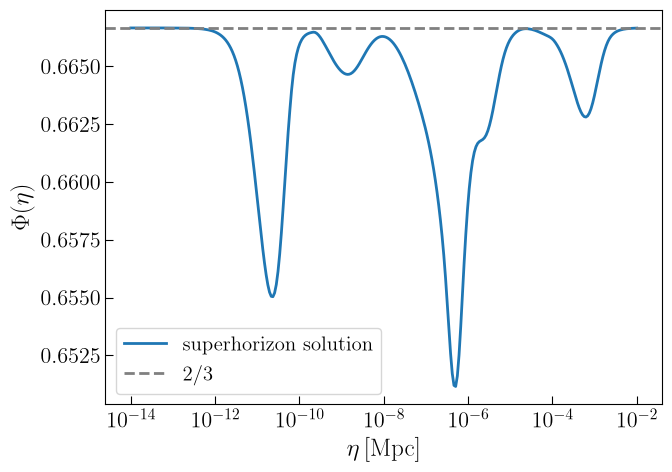

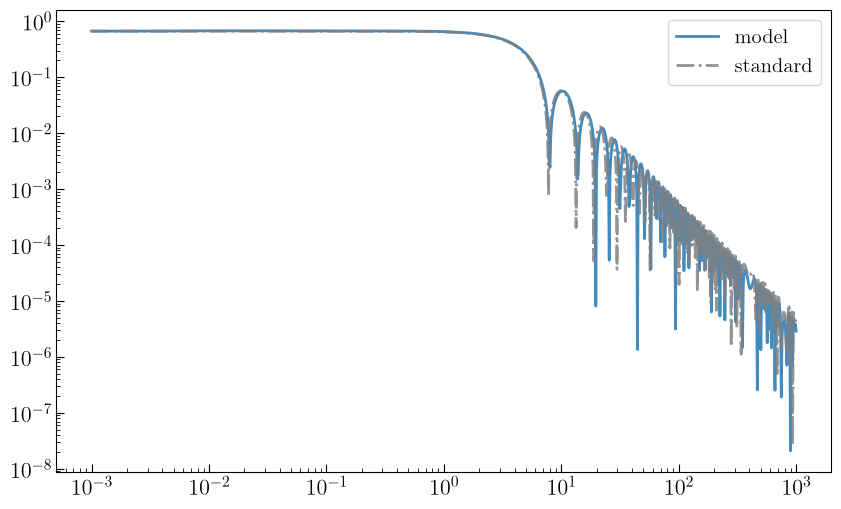

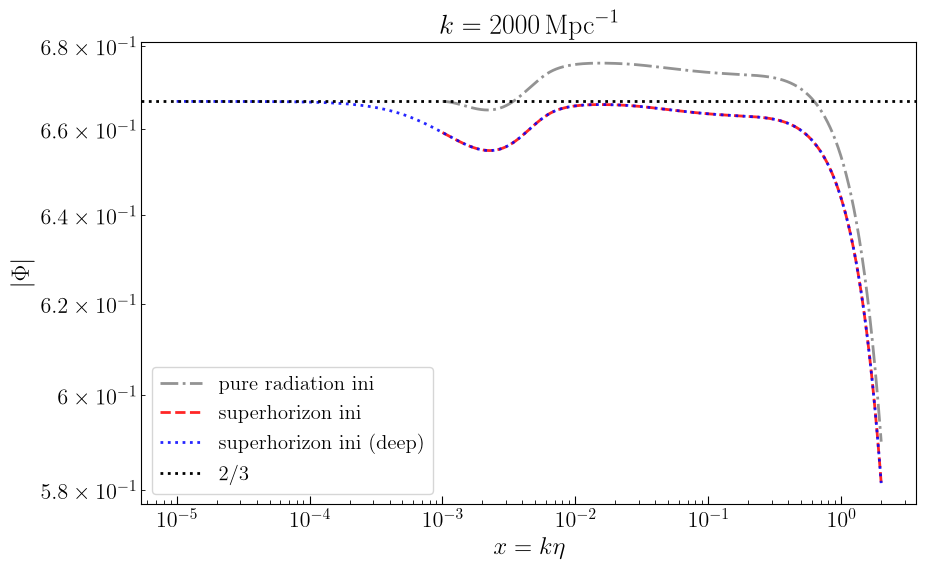

In [33]:
# This cell requires the updated solver definition above.  In a live Jupyter
# kernel, rerun that definition cell after editing the notebook.
import inspect
if 'initial_condition' not in inspect.signature(solve_phi_transfer).parameters:
    raise RuntimeError(
        'The kernel still has the old solve_phi_transfer definition. '
        'Rerun the Phi solver-definition cell above, then rerun this cell.'
    )

eta_span = np.geomspace(1e-14, 1e-2, 300)
superhorizon_fractional_shift = np.array([
    superhorizon_mode(eta)
    for eta in eta_span
])
plt.figure(figsize=(7, 5))
plt.plot(eta_span, superhorizon_fractional_shift, label='superhorizon solution')
plt.axhline(2/3, color='gray', ls='--', label='2/3')
plt.xlabel(r'$\eta\,[\mathrm{Mpc}]$')
plt.xscale('log')
plt.ylabel(r'$\Phi(\eta)$')
plt.legend()
plt.tight_layout()
plt.show()

k_value = 1e8
comparison_x = np.geomspace(1e-3,1e+3,1000)
phi_radiation, _ = solve_phi_transfer(
        k_value, x_grid=comparison_x, initial_condition='pure_radiation'
)
plt.loglog(comparison_x, abs(phi_radiation),
              alpha=0.85, label='model')
plt.loglog(comparison_x, abs(phi_ana(k_value,comparison_x/k_value)), color = 'gray',alpha=0.85, ls='-.', label = 'standard')
plt.legend()
plt.show()

k_value = 1e8
comparison_x = np.geomspace(1e-3,2,1000)
comparison_x_deep = np.geomspace(1e-5,2,1200)
phi_radiation, _ = solve_phi_transfer(
        k_value, x_grid=comparison_x, initial_condition='pure_radiation'
)
phi_superhorizon, _ = solve_phi_transfer(
        k_value, x_grid=comparison_x, initial_condition='analytic_superhorizon_v1'
)
phi_superhorizon_deep, _ = solve_phi_transfer(
        k_value, x_grid=comparison_x_deep, initial_condition='analytic_superhorizon_v1'
)
plt.loglog(comparison_x, abs(phi_radiation), color = 'gray',alpha=0.85, ls='-.', label = 'pure radiation ini')
plt.loglog(comparison_x, abs(phi_superhorizon), color = 'red',alpha=0.85, ls='--', label = 'superhorizon ini')
plt.loglog(comparison_x_deep, abs(phi_superhorizon_deep), color = 'blue',alpha=0.85, ls=':', label = 'superhorizon ini (deep)')
plt.xlabel(r'$x=k\eta$')
plt.ylabel(r'$|\Phi|$ per unit primordial curvature')
plt.title(r'$k=2000\,\mathrm{Mpc}^{-1}$')
plt.axhline(2/3, color='black', ls=':', label = '2/3')
plt.legend()

plt.xlabel(r'$x=k\eta$')
plt.ylabel(r'$|\Phi|$')
plt.show()


In [34]:
# Set this to True to regenerate missing/incompatible scalar transfer chunks.
# This can take a long time for the 1e6-1e8 chunk because it has many k modes.
if PHI_INITIAL_CONDITION not in {'analytic_superhorizon_v1', 'pure_radiation'}:
    raise ValueError(f'Unsupported PHI_INITIAL_CONDITION: {PHI_INITIAL_CONDITION!r}')
print(f'Phi cache initial condition: {PHI_INITIAL_CONDITION}')
RUN_PHI_PRECOMPUTE = True
if RUN_PHI_PRECOMPUTE:
    generate_missing_phi_chunks()
else:
    missing = [c.label for c in PHI_CHUNKS if not (_chunk_paths(c)['phi'].exists() and _chunk_paths(c)['phi_prime'].exists())]
    print('Phi precompute skipped. Missing updated-cache chunks:', missing)
    print('Old-background Phi chunks are not compatible with the thermal background.')


Phi cache initial condition: analytic_superhorizon_v1
Phi chunk 02 already exists with initial_condition=analytic_superhorizon_v1; reusing it
Phi chunk 24 already exists with initial_condition=analytic_superhorizon_v1; reusing it
Phi chunk 46 already exists with initial_condition=analytic_superhorizon_v1; reusing it
Phi chunk 68 already exists with initial_condition=analytic_superhorizon_v1; reusing it
Phi chunk 810 already exists with initial_condition=analytic_superhorizon_v1; reusing it
Phi chunk 1014 already exists with initial_condition=analytic_superhorizon_v1; reusing it
Phi chunk 1416 already exists with initial_condition=analytic_superhorizon_v1; reusing it


In [35]:
def _interp_rows_on_log_grid(values, x_grid, x_query):
    """Fast local cubic interpolation for one cached curve per query row."""
    values = np.asarray(values, dtype=float)
    x_grid = np.asarray(x_grid, dtype=float)
    x_query = np.asarray(x_query, dtype=float)
    if values.ndim != 2 or x_query.ndim != 2 or values.shape[0] != x_query.shape[0]:
        raise ValueError('values and x_query must be 2-D arrays with matching row counts.')

    rtol = 1e-10
    atol = 1e-14
    if np.any(x_query < x_grid[0] * (1.0 - rtol) - atol) or np.any(x_query > x_grid[-1] * (1.0 + rtol) + atol):
        raise ValueError(
            f'Prepared transfer requested outside x=[{x_grid[0]:.6g}, {x_grid[-1]:.6g}]'
        )
    x_clipped = np.clip(x_query, x_grid[0], x_grid[-1])
    log_x0 = math.log(x_grid[0])
    dlog_x = math.log(x_grid[-1] / x_grid[0]) / (len(x_grid) - 1)
    position = (np.log(x_clipped) - log_x0) / dlog_x
    i0 = np.clip(np.floor(position).astype(np.int64) - 1, 0, len(x_grid) - 4)
    z = position - i0

    # Four-point Lagrange interpolation on the uniform log(x) cache grid.
    out = np.take_along_axis(values, i0, axis=1)
    out *= -((z - 1.0) * (z - 2.0) * (z - 3.0)) / 6.0
    sample = np.take_along_axis(values, i0 + 1, axis=1)
    out += sample * (z * (z - 2.0) * (z - 3.0)) / 2.0
    sample = np.take_along_axis(values, i0 + 2, axis=1)
    out -= sample * (z * (z - 1.0) * (z - 3.0)) / 2.0
    sample = np.take_along_axis(values, i0 + 3, axis=1)
    out += sample * (z * (z - 1.0) * (z - 2.0)) / 6.0
    return out


def _interp_one_on_log_grid(values, x_grid, x_query):
    """Fast local cubic interpolation of one cached curve at an array of x."""
    query = np.asarray(x_query, dtype=float)
    flat = query.reshape(1, -1)
    repeated_values = np.asarray(values, dtype=float).reshape(1, -1)
    return _interp_rows_on_log_grid(repeated_values, x_grid, flat).reshape(query.shape)


class RowwiseCubicHermite:
    """Coupled value/derivative interpolation for one query grid per row."""
    def __init__(self, x_grid, values, derivatives):
        self.x_grid = np.asarray(x_grid, dtype=float)
        self.values = np.asarray(values, dtype=float)
        self.derivatives = np.asarray(derivatives, dtype=float)
        if self.values.shape != self.derivatives.shape or self.values.shape[1] != len(self.x_grid):
            raise ValueError('Hermite values and derivatives must match the x grid.')

    def _interval_data(self, x_query):
        x_query = np.asarray(x_query, dtype=float)
        if x_query.ndim != 2 or x_query.shape[0] != self.values.shape[0]:
            raise ValueError('Hermite transfer queries must be 2-D with one row per prepared mode.')
        rtol = 1e-10
        atol = 1e-14
        if (
            np.any(x_query < self.x_grid[0] * (1.0 - rtol) - atol)
            or np.any(x_query > self.x_grid[-1] * (1.0 + rtol) + atol)
        ):
            raise ValueError(
                f'Prepared transfer requested outside x=[{self.x_grid[0]:.6g}, {self.x_grid[-1]:.6g}]'
            )
        x_query = np.clip(x_query, self.x_grid[0], self.x_grid[-1])
        interval = np.searchsorted(self.x_grid, x_query, side='right') - 1
        interval = np.clip(interval, 0, len(self.x_grid) - 2)
        x0 = self.x_grid[interval]
        h = self.x_grid[interval + 1] - x0
        z = (x_query - x0) / h
        y0 = np.take_along_axis(self.values[:, :-1], interval, axis=1)
        y1 = np.take_along_axis(self.values[:, 1:], interval, axis=1)
        m0 = np.take_along_axis(self.derivatives[:, :-1], interval, axis=1)
        m1 = np.take_along_axis(self.derivatives[:, 1:], interval, axis=1)
        return z, h, y0, y1, m0, m1

    def value(self, x_query):
        z, h, y0, y1, m0, m1 = self._interval_data(x_query)
        z2 = z * z
        z3 = z2 * z
        return (
            (2.0 * z3 - 3.0 * z2 + 1.0) * y0
            + (z3 - 2.0 * z2 + z) * h * m0
            + (-2.0 * z3 + 3.0 * z2) * y1
            + (z3 - z2) * h * m1
        )

    def derivative(self, x_query):
        z, h, y0, y1, m0, m1 = self._interval_data(x_query)
        z2 = z * z
        return (
            (6.0 * z2 - 6.0 * z) * y0 / h
            + (3.0 * z2 - 4.0 * z + 1.0) * m0
            + (-6.0 * z2 + 6.0 * z) * y1 / h
            + (3.0 * z2 - 2.0 * z) * m1
        )


class PreparedRowwisePhi:
    def __init__(self, x_grid, phi, phi_prime_eta, mode_k):
        self.mode_k = np.asarray(mode_k, dtype=float)
        self.hermite = RowwiseCubicHermite(
            x_grid,
            phi,
            np.asarray(phi_prime_eta, dtype=float) / self.mode_k[:, None],
        )

    def phi(self, x_query):
        return self.hermite.value(x_query)

    def phi_prime(self, x_query):
        shape = (len(self.mode_k),) + (1,) * (np.ndim(x_query) - 1)
        return self.hermite.derivative(x_query) * self.mode_k.reshape(shape)


class PreparedPhiModes:
    def __init__(self, groups, shape):
        self.groups = groups
        self.shape = tuple(shape)

    def _eval(self, x, key):
        x = np.asarray(x, dtype=float)
        if x.shape[0] != self.shape[0]:
            raise ValueError('Prepared Phi rows no longer match the requested scalar modes.')
        out = np.empty_like(x, dtype=float)
        for group in self.groups:
            rows = group['rows']
            out[rows] = group[key](x[rows])
        return out

    def phi(self, x):
        return self._eval(x, 'phi')

    def phi_prime(self, x):
        return self._eval(x, 'phi_prime')


class PreparedPhiPair:
    def __init__(self, u_modes, v_modes):
        self.u_modes = u_modes
        self.v_modes = v_modes


class PiecewisePhiTransfer:
    def __init__(
        self,
        chunks=PHI_CHUNKS,
        prefer_updated=True,
        cache_dir=PHI_CACHE_DIR,
        allow_original=False,
    ):
        self.entries = []
        self.cache_dir = Path(cache_dir)
        for chunk in chunks:
            updated = _chunk_paths(chunk, directory=self.cache_dir)
            original_phi = DATA_DIR / f'Phi_mat_{chunk.label}.npy'
            original_prime = DATA_DIR / f'Phi_prime_mat_{chunk.label}.npy'
            if prefer_updated and _phi_cache_compatible(chunk, directory=self.cache_dir):
                phi_path = updated['phi']
                prime_path = updated['phi_prime']
                meta_path = updated['meta']
            elif allow_original and original_phi.exists() and original_prime.exists():
                phi_path = original_phi
                prime_path = original_prime
                meta_path = None
            else:
                continue

            phi = np.load(phi_path, mmap_mode='r')
            phi_prime = np.load(prime_path, mmap_mode='r')
            if phi.shape != phi_prime.shape:
                raise ValueError(f'Shape mismatch in Phi chunk {chunk.label}')
            if meta_path and meta_path.exists():
                meta = json.loads(meta_path.read_text())
                k_grid = np.geomspace(meta['k_min'], meta['k_max'], meta['n_k'])
                x_grid = np.geomspace(meta['x_ini'], meta['x_final'], meta['n_x'])
            else:
                k_grid = np.geomspace(chunk.k_min, chunk.k_max, phi.shape[0])
                x_grid = np.geomspace(X_INI, X_FINAL, phi.shape[1])
            self.entries.append({
                'label': chunk.label,
                'k_min': float(k_grid[0]),
                'k_max': float(k_grid[-1]),
                'x_min': float(x_grid[0]),
                'x_max': float(x_grid[-1]),
                'x_grid': x_grid,
                'phi_interp': RectBivariateSpline(np.log10(k_grid), x_grid, phi, kx=3, ky=3, s=0),
                'prime_interp': RectBivariateSpline(np.log10(k_grid), x_grid, phi_prime, kx=3, ky=3, s=0),
            })
        if not self.entries:
            raise FileNotFoundError('No Phi chunks were found. Generate them first with RUN_PHI_PRECOMPUTE=True.')
        print('Loaded Phi chunks:', [e['label'] for e in self.entries])

    def _eval(self, k, x, key):
        k_arr, x_arr = np.broadcast_arrays(np.asarray(k, dtype=float), np.asarray(x, dtype=float))
        out = np.full(k_arr.shape, np.nan, dtype=float)
        k_flat = k_arr.ravel()
        x_flat = x_arr.ravel()
        out_flat = out.ravel()
        rtol = 1e-10
        atol = 1e-14
        for entry in self.entries:
            k_min, k_max = entry['k_min'], entry['k_max']
            x_min, x_max = entry['x_min'], entry['x_max']
            mask = (
                (k_flat >= k_min * (1.0 - rtol)) & (k_flat <= k_max * (1.0 + rtol)) &
                (x_flat >= x_min * (1.0 - rtol) - atol) & (x_flat <= x_max * (1.0 + rtol) + atol)
            )
            if np.any(mask):
                k_eval = np.clip(k_flat[mask], k_min, k_max)
                x_eval = np.clip(x_flat[mask], x_min, x_max)
                out_flat[mask] = entry[key].ev(np.log10(k_eval), x_eval)
        if np.any(~np.isfinite(out_flat)):
            bad = np.where(~np.isfinite(out_flat))[0][0]
            loaded = ', '.join(
                f"{e['label']}: k=[{e['k_min']:.3g}, {e['k_max']:.3g}], x=[{e['x_min']:.3g}, {e['x_max']:.3g}]"
                for e in self.entries
            )
            raise ValueError(
                f'Phi transfer requested outside cached range: k={k_flat[bad]:.12g}, x={x_flat[bad]:.12g}. '
                f'Loaded chunks: {loaded}. Generate a wider Phi chunk or reduce integration bounds.'
            )
        return float(out) if np.isscalar(k) and np.isscalar(x) else out

    def covers_k_range(self, k_min, k_max, rtol=1e-10):
        intervals = sorted((entry['k_min'], entry['k_max']) for entry in self.entries)
        target = float(k_min)
        end = float(k_max)
        for lo, hi in intervals:
            if hi < target * (1.0 - rtol):
                continue
            if lo > target * (1.0 + rtol):
                return False
            target = max(target, hi)
            if target >= end * (1.0 - rtol):
                return True
        return False

    def phi(self, k, x):
        return self._eval(k, x, 'phi_interp')

    def phi_prime(self, k, x):
        return self._eval(k, x, 'prime_interp')

    def prepare_modes(self, k_values):
        k_values = np.asarray(k_values, dtype=float).reshape(-1)
        entry_index = np.full(k_values.shape, -1, dtype=int)
        rtol = 1e-10
        for index, entry in enumerate(self.entries):
            mask = (
                (k_values >= entry['k_min'] * (1.0 - rtol))
                & (k_values <= entry['k_max'] * (1.0 + rtol))
            )
            entry_index[mask] = index
        if np.any(entry_index < 0):
            bad = int(np.where(entry_index < 0)[0][0])
            raise ValueError(f'Cannot prepare Phi transfer for k={k_values[bad]:.12g}.')

        groups = []
        for index in np.unique(entry_index):
            entry = self.entries[int(index)]
            rows = np.where(entry_index == index)[0]
            k_eval = np.clip(k_values[rows], entry['k_min'], entry['k_max'])
            unique_logk, inverse = np.unique(np.log10(k_eval), return_inverse=True)
            x_grid = entry['x_grid']
            phi_unique = entry['phi_interp'](unique_logk, x_grid, grid=True)
            prime_unique = entry['prime_interp'](unique_logk, x_grid, grid=True)
            transfer = PreparedRowwisePhi(
                x_grid,
                phi_unique[inverse],
                prime_unique[inverse],
                k_eval,
            )
            groups.append({
                'rows': rows,
                'x_grid': x_grid,
                'phi': transfer.phi,
                'phi_prime': transfer.phi_prime,
            })
        return PreparedPhiModes(groups, k_values.shape)

    def prepare_pair(self, u_values, v_values, tensor_k):
        return PreparedPhiPair(
            self.prepare_modes(np.asarray(u_values, dtype=float) * float(tensor_k)),
            self.prepare_modes(np.asarray(v_values, dtype=float) * float(tensor_k)),
        )


# Load explicitly after the needed Phi chunks exist. This avoids building large
# spline objects just by opening/running the notebook header.
LOAD_PHI_CACHE_NOW = True
phi_cache = PiecewisePhiTransfer() if LOAD_PHI_CACHE_NOW else None


Loaded Phi chunks: ['02', '24', '46', '68', '810', '1014', '1416']


## Tensor Green function

For the variable `g = a h`, the homogeneous equation is

\[
g_k'' + \left[k^2 - \frac{1-3w}{2}\mathcal{H}^2\right]g_k = 0.
\]

The derivative matrices below store `dg/deta`, so the Wronskian in the Green function has the correct conformal-time normalization.


In [36]:
GREEN_CHUNKS = [
    # Retain the established middle chunk and extend both ends at 100 points/dex.
    TransferChunk('23', 1e2, 1e3, 100),
    TransferChunk('314', 1e3, 1e14, 1100),
]
GREEN_RTOL = 3e-8
GREEN_ATOL = 1e-10
GREEN_X_FINAL = 1000.0  # Legacy cache endpoint; x>30 uses harmonic extension.
GREEN_HARMONIC_FROM = 30.0


def green_rhs_x(x, y, k):
    g, dg_dx = y
    eta = x / k
    d2g_dx2 = -(1.0 - tensor_mass_over_k2(eta, k)) * g
    return [dg_dx, d2g_dx2]


def solve_green_modes(k, x_grid=None, rtol=GREEN_RTOL, atol=GREEN_ATOL):
    if x_grid is None:
        x_grid = np.geomspace(X_INI, GREEN_X_FINAL, N_X_DEFAULT)
    x0 = float(x_grid[0])
    # Two independent superhorizon-like basis functions. Only independence
    # matters for the Green function; the Wronskian handles normalization.
    y0_1 = [x0, 1.0]
    y0_2 = [1.0, 0.0]
    sol1 = solve_ivp(green_rhs_x, (x_grid[0], x_grid[-1]), y0_1, t_eval=x_grid, args=(float(k),), method='DOP853', rtol=rtol, atol=atol)
    sol2 = solve_ivp(green_rhs_x, (x_grid[0], x_grid[-1]), y0_2, t_eval=x_grid, args=(float(k),), method='DOP853', rtol=rtol, atol=atol)
    if not sol1.success:
        raise RuntimeError(f'Green mode 1 failed for k={k:.6g}: {sol1.message}')
    if not sol2.success:
        raise RuntimeError(f'Green mode 2 failed for k={k:.6g}: {sol2.message}')
    return sol1.y[0], float(k) * sol1.y[1], sol2.y[0], float(k) * sol2.y[1]


def _green_chunk_paths(chunk, directory=GREEN_CACHE_DIR):
    return {
        'g1': directory / f'g1_mat_{chunk.label}.npy',
        'g1_prime': directory / f'g1_prime_mat_{chunk.label}.npy',
        'g2': directory / f'g2_mat_{chunk.label}.npy',
        'g2_prime': directory / f'g2_prime_mat_{chunk.label}.npy',
        'meta': directory / f'green_meta_{chunk.label}.json',
    }


def save_green_chunk(chunk, n_x=N_X_DEFAULT, overwrite=False):
    paths = _green_chunk_paths(chunk)
    if not overwrite and all(paths[key].exists() for key in ('g1', 'g1_prime', 'g2', 'g2_prime')):
        # Reuse the established full-EoS Green cache.
        print(f'Green chunk {chunk.label} already exists; reusing it')
        return
    x_grid = np.geomspace(X_INI, GREEN_X_FINAL, int(n_x))
    k_grid = np.geomspace(chunk.k_min, chunk.k_max, chunk.n_k)
    mats = [np.empty((chunk.n_k, int(n_x)), dtype=np.float64) for _ in range(4)]
    for i, k in enumerate(k_grid, start=1):
        g1, g1p, g2, g2p = solve_green_modes(k, x_grid=x_grid)
        mats[0][i - 1] = g1
        mats[1][i - 1] = g1p
        mats[2][i - 1] = g2
        mats[3][i - 1] = g2p
        if i == 1 or i == chunk.n_k or i % max(1, chunk.n_k // 20) == 0:
            print(f'Green {chunk.label}: {i}/{chunk.n_k}')
    for key, mat in zip(('g1', 'g1_prime', 'g2', 'g2_prime'), mats):
        np.save(paths[key], mat)
    paths['meta'].write_text(json.dumps({
        'label': chunk.label,
        'k_min': chunk.k_min,
        'k_max': chunk.k_max,
        'n_k': chunk.n_k,
        'x_ini': X_INI,
        'x_final': GREEN_X_FINAL,
        'n_x': int(n_x),
        'prime': 'dg/deta',
        'tensor_include_w_correction': bool(TENSOR_INCLUDE_W_CORRECTION),
    }, indent=2))


def generate_missing_green_chunks(chunks=GREEN_CHUNKS, n_x=N_X_DEFAULT):
    for chunk in chunks:
        save_green_chunk(chunk, n_x=n_x, overwrite=False)


In [37]:
RUN_GREEN_PRECOMPUTE = True
if RUN_GREEN_PRECOMPUTE:
    generate_missing_green_chunks()
else:
    missing = [c.label for c in GREEN_CHUNKS if not all(_green_chunk_paths(c)[key].exists() for key in ('g1', 'g1_prime', 'g2', 'g2_prime'))]
    print('Green precompute skipped. Missing updated-cache chunks:', missing)


Green chunk 23 already exists; reusing it
Green chunk 314 already exists; reusing it


In [38]:
class PreparedGreenAtK:
    """Green basis interpolated from the complete ODE solution cache.

    The cache is generated by ``solve_green_modes`` using the full background
    equation through x=30; later x uses a harmonic continuation.
    """
    def __init__(self, k, entry):
        self.k = float(k)
        self.entry = entry
        self.x_grid = entry['x_grid']
        logk = math.log10(float(np.clip(k, entry['k_min'], entry['k_max'])))
        values = {
            key: entry[key](np.array([logk]), self.x_grid, grid=True)[0]
            for key in ('g1', 'g1p', 'g2', 'g2p')
        }
        self.mode1 = CubicHermiteSpline(
            self.x_grid, values['g1'], values['g1p'] / self.k,
            extrapolate=False,
        )
        self.mode2 = CubicHermiteSpline(
            self.x_grid, values['g2'], values['g2p'] / self.k,
            extrapolate=False,
        )
        self.mode1_at_switch = (float(self.mode1(GREEN_HARMONIC_FROM)), float(self.mode1(GREEN_HARMONIC_FROM, nu=1)))
        self.mode2_at_switch = (float(self.mode2(GREEN_HARMONIC_FROM)), float(self.mode2(GREEN_HARMONIC_FROM, nu=1)))
        self.basis = {
            'g1': lambda x: self._eval_mode(self.mode1, self.mode1_at_switch, x),
            'g1p': lambda x: self._eval_mode_prime(self.mode1, self.mode1_at_switch, x),
            'g2': lambda x: self._eval_mode(self.mode2, self.mode2_at_switch, x),
            'g2p': lambda x: self._eval_mode_prime(self.mode2, self.mode2_at_switch, x),
        }

    def _eval_mode(self, mode, anchor, x):
        x = np.asarray(x, dtype=float)
        early = x <= GREEN_HARMONIC_FROM
        return np.where(early, mode(np.minimum(x, GREEN_HARMONIC_FROM)),
                        anchor[0] * np.cos(x - GREEN_HARMONIC_FROM)
                        + anchor[1] * np.sin(x - GREEN_HARMONIC_FROM))

    def _eval_mode_prime(self, mode, anchor, x):
        x = np.asarray(x, dtype=float)
        early = x <= GREEN_HARMONIC_FROM
        return self.k * np.where(early, mode(np.minimum(x, GREEN_HARMONIC_FROM), nu=1),
                                 -anchor[0] * np.sin(x - GREEN_HARMONIC_FROM)
                                 + anchor[1] * np.cos(x - GREEN_HARMONIC_FROM))

    def green(self, eta_bar, eta, k):
        if not np.isclose(float(k), self.k, rtol=1e-12, atol=0.0):
            raise ValueError(f'Prepared Green k={self.k:.12g} cannot evaluate k={float(k):.12g}.')
        x_bar = np.asarray(eta_bar, dtype=float) * self.k
        x = np.asarray(eta, dtype=float) * self.k
        x_all = np.concatenate([np.ravel(x_bar), np.ravel(x)])
        x_min_req = float(np.nanmin(x_all))
        if x_min_req < self.entry['x_min'] * (1.0 - 1e-10) - 1e-12:
            raise ValueError(
                f'Prepared Green requested outside cached x range '
                f'[{self.entry["x_min"]:.6g}, {self.entry["x_max"]:.6g}]'
            )
        x_bar = np.maximum(x_bar, self.entry['x_min'])
        x = np.maximum(np.broadcast_to(x, x_bar.shape), self.entry['x_min'])
        g1_bar = self.basis['g1'](x_bar)
        g1p_bar = self.basis['g1p'](x_bar)
        g2_bar = self.basis['g2'](x_bar)
        g2p_bar = self.basis['g2p'](x_bar)
        g1_eval = self.basis['g1'](x)
        g2_eval = self.basis['g2'](x)
        W = g1p_bar * g2_bar - g1_bar * g2p_bar
        return (g1_eval * g2_bar - g1_bar * g2_eval) / W


class PiecewiseGreen:
    def __init__(self, chunks=GREEN_CHUNKS, cache_dir=GREEN_CACHE_DIR):
        self.entries = []
        self.cache_dir = Path(cache_dir)
        for chunk in chunks:
            paths = _green_chunk_paths(chunk, directory=self.cache_dir)
            if not all(paths[key].exists() for key in ('g1', 'g1_prime', 'g2', 'g2_prime')):
                continue
            g1 = np.load(paths['g1'], mmap_mode='r')
            g1p = np.load(paths['g1_prime'], mmap_mode='r')
            g2 = np.load(paths['g2'], mmap_mode='r')
            g2p = np.load(paths['g2_prime'], mmap_mode='r')
            if paths['meta'].exists():
                meta = json.loads(paths['meta'].read_text())
                k_grid = np.geomspace(meta['k_min'], meta['k_max'], meta['n_k'])
                x_grid = np.geomspace(meta['x_ini'], meta['x_final'], meta['n_x'])
            else:
                k_grid = np.geomspace(chunk.k_min, chunk.k_max, g1.shape[0])
                x_grid = np.geomspace(X_INI, GREEN_X_FINAL, g1.shape[1])
            self.entries.append({
                'label': chunk.label,
                'k_min': float(k_grid[0]),
                'k_max': float(k_grid[-1]),
                'x_min': float(x_grid[0]),
                'x_max': float(x_grid[-1]),
                'x_grid': x_grid,
                'g1': RectBivariateSpline(np.log10(k_grid), x_grid, g1, kx=3, ky=3, s=0),
                'g1p': RectBivariateSpline(np.log10(k_grid), x_grid, g1p, kx=3, ky=3, s=0),
                'g2': RectBivariateSpline(np.log10(k_grid), x_grid, g2, kx=3, ky=3, s=0),
                'g2p': RectBivariateSpline(np.log10(k_grid), x_grid, g2p, kx=3, ky=3, s=0),
            })
        if not self.entries:
            raise FileNotFoundError('No Green chunks were found. Generate them first with RUN_GREEN_PRECOMPUTE=True.')
        print('Loaded Green chunks:', [e['label'] for e in self.entries])

    def _entry_for(self, k, x_values, rtol=1e-10, atol=1e-12):
        k = float(k)
        x_values = np.asarray(x_values, dtype=float)
        x_min_req = float(np.nanmin(x_values))
        x_max_req = float(np.nanmax(x_values))
        for entry in self.entries:
            k_min, k_max = entry['k_min'], entry['k_max']
            x_min, x_max = entry['x_min'], entry['x_max']
            k_ok = (k >= k_min * (1.0 - rtol)) and (k <= k_max * (1.0 + rtol))
            x_ok = (x_min_req >= x_min * (1.0 - rtol) - atol) and (x_max_req <= x_max * (1.0 + rtol) + atol)
            if k_ok and x_ok:
                return entry
        loaded = ', '.join(
            f"{e['label']}: k=[{e['k_min']:.3g}, {e['k_max']:.3g}], x=[{e['x_min']:.3g}, {e['x_max']:.3g}]"
            for e in self.entries
        )
        raise ValueError(
            f'Green function requested outside cached range for k={k:.12g}, x=[{x_min_req:.12g}, {x_max_req:.12g}]. '
            f'Loaded chunks: {loaded}. Generate a wider Green chunk or reduce integration bounds.'
        )

    def green(self, eta_bar, eta, k):
        k = float(k)
        x_bar = np.asarray(eta_bar, dtype=float) * k
        x = np.asarray(eta, dtype=float) * k
        entry = self._entry_for(k, np.concatenate([np.ravel(x_bar), np.ravel(x)]))
        k_eval = float(np.clip(k, entry['k_min'], entry['k_max']))
        logk = math.log10(k_eval)
        x_bar_eval = np.clip(x_bar, entry['x_min'], entry['x_max'])
        logk_bar = np.full(np.ravel(x_bar_eval).shape, logk)
        g1_bar = entry['g1'].ev(logk_bar, np.ravel(x_bar_eval)).reshape(x_bar.shape)
        g1p_bar = entry['g1p'].ev(logk_bar, np.ravel(x_bar_eval)).reshape(x_bar.shape)
        g2_bar = entry['g2'].ev(logk_bar, np.ravel(x_bar_eval)).reshape(x_bar.shape)
        g2p_bar = entry['g2p'].ev(logk_bar, np.ravel(x_bar_eval)).reshape(x_bar.shape)
        x_eval = np.broadcast_to(x, x_bar.shape)
        x_eval_clipped = np.clip(x_eval, entry['x_min'], entry['x_max'])
        logk_eval = np.full(np.ravel(x_eval_clipped).shape, logk)
        g1_eval = entry['g1'].ev(logk_eval, np.ravel(x_eval_clipped)).reshape(x_bar.shape)
        g2_eval = entry['g2'].ev(logk_eval, np.ravel(x_eval_clipped)).reshape(x_bar.shape)
        W = g1p_bar * g2_bar - g1_bar * g2p_bar
        return (g1_eval * g2_bar - g1_bar * g2_eval) / W

    def prepare_k(self, k):
        entry = self._entry_for(float(k), [X_INI, GREEN_HARMONIC_FROM])
        return PreparedGreenAtK(float(k), entry)


def load_green_cache():
    return PiecewiseGreen()


## Source, time kernel, and kernel-grid cache

The source factor below is the `f` appearing in the Domenech review convention, but with the initial Newtonian-potential-to-curvature factor absorbed into `Phi`. Therefore the momentum integral should use `P_zeta`, not `P_Phi`.


In [39]:
def source_f_per_zeta(u, v, k, x_tensor, phi_transfer=None, prepared_phi=None):
    if phi_transfer is None and prepared_phi is None:
        raise ValueError('Pass phi_transfer=PiecewisePhiTransfer() after the Phi chunks have been generated/loaded.')
    eta = np.asarray(x_tensor, dtype=float) / float(k)
    H = conH_interp(eta)
    w = eos(eta)
    if prepared_phi is None:
        phi_u = phi_transfer.phi(u * k, u * x_tensor)
        phi_v = phi_transfer.phi(v * k, v * x_tensor)
        dphi_u = phi_transfer.phi_prime(u * k, u * x_tensor)
        dphi_v = phi_transfer.phi_prime(v * k, v * x_tensor)
    else:
        phi_u = prepared_phi.u_modes.phi(u * x_tensor)
        phi_v = prepared_phi.v_modes.phi(v * x_tensor)
        dphi_u = prepared_phi.u_modes.phi_prime(u * x_tensor)
        dphi_v = prepared_phi.v_modes.phi_prime(v * x_tensor)

    one_plus_w = 1.0 + w
    return (
        (5.0 + 3.0 * w) / (3.0 * one_plus_w) * phi_u * phi_v
        + 2.0 / (3.0 * one_plus_w) * (dphi_u * phi_v + dphi_v * phi_u) / H
        + 2.0 / (3.0 * one_plus_w) * dphi_u * dphi_v / H**2
    )


def choose_eta_min(u, v, k, x_min=X_INI, margin=1e-8):
    # Keep tensor and both scalar transfer-function arguments inside the cache.
    # The small margin avoids starting exactly on x_min, where roundoff can put
    # u*x or v*x a few ulps below the first cached grid point.
    smallest_multiplier = min(1.0, float(u), float(v))
    return x_min * (1.0 + margin) / (float(k) * smallest_multiplier)


def I_func_eta(u, v, k, eta, green_cache, phi_transfer=None, n_time=3000):
    eta_min = choose_eta_min(u, v, k)
    if eta <= eta_min:
        raise ValueError(f'eta={eta:.6g} is not larger than eta_min={eta_min:.6g}')
    eta_grid = np.geomspace(eta_min, eta, int(n_time))
    x_grid = float(k) * eta_grid
    integrand = (
        float(k)**2
        * a_interp(eta_grid) / a_interp(eta)
        * green_cache.green(eta_grid, eta, k)
        * source_f_per_zeta(u, v, k, x_grid, phi_transfer=phi_transfer)
    )
    return trapezoid(integrand, eta_grid)


def kernel_scaled_I2(u, v, k, green_cache, phi_transfer=None, x_eval=1e3, n_time=3000):
    # Returns (k / calH_c)^2 * average[I^2] at a time after source decay.
    # eta_c follows the original notebook's practical choice to keep scalar
    # arguments inside x <= x_eval for large u or v.
    max_mode = max(1.0, float(u), float(v))
    eta1 = float(x_eval) / (float(k) * max_mode)
    eta2 = eta1 - math.pi / (2.0 * float(k))
    if eta2 <= choose_eta_min(u, v, k):
        eta2 = eta1 + math.pi / (2.0 * float(k))
    I1 = I_func_eta(u, v, k, eta1, green_cache, phi_transfer=phi_transfer, n_time=n_time)
    I2 = I_func_eta(u, v, k, eta2, green_cache, phi_transfer=phi_transfer, n_time=n_time)
    avg_I2 = 0.5 * (I1**2 + I2**2)
    return avg_I2 * (float(k) / conH_interp(eta1))**2



def choose_eta_min_many(u, v, k, x_min=X_INI, margin=1e-8):
    u = np.asarray(u, dtype=float)
    v = np.asarray(v, dtype=float)
    smallest_multiplier = np.minimum(1.0, np.minimum(u, v))
    return x_min * (1.0 + margin) / (float(k) * smallest_multiplier)


def I_func_eta_many(
    u_values,
    v_values,
    k,
    eta_values,
    green_cache,
    phi_transfer=None,
    n_time=3000,
    prepared_phi=None,
):
    u_values = np.asarray(u_values, dtype=float)
    v_values = np.asarray(v_values, dtype=float)
    eta_values = np.asarray(eta_values, dtype=float)
    eta_min = choose_eta_min_many(u_values, v_values, k)
    if np.any(eta_values <= eta_min):
        bad = np.where(eta_values <= eta_min)[0][0]
        raise ValueError(f'eta={eta_values[bad]:.6g} is not larger than eta_min={eta_min[bad]:.6g}')

    frac = np.linspace(0.0, 1.0, int(n_time))
    log_eta_min = np.log(eta_min)[:, None]
    log_eta_max = np.log(eta_values)[:, None]
    eta_grid = np.exp(log_eta_min + (log_eta_max - log_eta_min) * frac[None, :])
    x_grid = float(k) * eta_grid
    u_col = u_values[:, None]
    v_col = v_values[:, None]

    integrand = (
        float(k)**2
        * a_interp(eta_grid) / a_interp(eta_values)[:, None]
        * green_cache.green(eta_grid, eta_values[:, None], k)
        * source_f_per_zeta(
            u_col,
            v_col,
            k,
            x_grid,
            phi_transfer=phi_transfer,
            prepared_phi=prepared_phi,
        )
    )
    return trapezoid(integrand, eta_grid, axis=1)


def kernel_scaled_I2_many(u_values, v_values, k, green_cache, phi_transfer=None, x_eval=1e3, n_time=3000):
    u_values = np.asarray(u_values, dtype=float)
    v_values = np.asarray(v_values, dtype=float)
    max_mode = np.maximum(1.0, np.maximum(u_values, v_values))
    eta1 = float(x_eval) / (float(k) * max_mode)
    eta2 = eta1 - math.pi / (2.0 * float(k))
    eta_min = choose_eta_min_many(u_values, v_values, k)
    eta2 = np.where(eta2 <= eta_min, eta1 + math.pi / (2.0 * float(k)), eta2)
    prepared_phi = (
        phi_transfer.prepare_pair(u_values, v_values, k)
        if hasattr(phi_transfer, 'prepare_pair')
        else None
    )
    prepared_green = green_cache.prepare_k(k) if hasattr(green_cache, 'prepare_k') else green_cache
    I1 = I_func_eta_many(
        u_values,
        v_values,
        k,
        eta1,
        prepared_green,
        phi_transfer=phi_transfer,
        n_time=n_time,
        prepared_phi=prepared_phi,
    )
    I2 = I_func_eta_many(
        u_values,
        v_values,
        k,
        eta2,
        prepared_green,
        phi_transfer=phi_transfer,
        n_time=n_time,
        prepared_phi=prepared_phi,
    )
    avg_I2 = 0.5 * (I1**2 + I2**2)
    return avg_I2 * (float(k) / conH_interp(eta1))**2


def _hybrid_source_eta_grid_many(eta_min, eta_end, k, n_time, x_switch=20.0):
    """Resolve both early logarithmic evolution and late oscillations."""
    eta_min = np.asarray(eta_min, dtype=float)
    eta_end = np.asarray(eta_end, dtype=float)
    n_time = int(n_time)
    if n_time < 512:
        raise ValueError('Hybrid source integration requires n_time >= 512.')

    x_min = float(k) * eta_min
    x_end = float(k) * eta_end
    n_log = min(max(256, n_time // 5), n_time - 2)
    n_linear = n_time - n_log + 1

    x_split = np.minimum(float(x_switch), 0.5 * x_end)
    x_split = np.maximum(x_split, x_min * (1.0 + 1e-10))
    x_split = np.minimum(x_split, x_end * (1.0 - 1e-10))

    early_fraction = np.linspace(0.0, 1.0, n_log)
    late_fraction = np.linspace(0.0, 1.0, n_linear)
    x_early = np.exp(
        np.log(x_min)[:, None]
        + (np.log(x_split) - np.log(x_min))[:, None] * early_fraction[None, :]
    )
    x_late = x_split[:, None] + (x_end - x_split)[:, None] * late_fraction[None, :]
    x_grid = np.concatenate([x_early[:, :-1], x_late], axis=1)
    return x_grid / float(k)


def kernel_scaled_I2_phase_average_many(
    u_values,
    v_values,
    k,
    green_cache,
    phi_transfer=None,
    x_source=1e3,
    n_time=6000,
    phase_periods=4,
    phase_samples=33,
):
    """Late-time kernel from frozen tensor-basis coefficients.

    The source is integrated once up to ``x_source`` for the fastest scalar
    mode. The resulting homogeneous tensor wave is then averaged over several
    I^2 periods, avoiding the phase bias of the original two-endpoint estimate.
    """
    u_values = np.asarray(u_values, dtype=float)
    v_values = np.asarray(v_values, dtype=float)
    if u_values.shape != v_values.shape or u_values.ndim != 1:
        raise ValueError('u_values and v_values must be one-dimensional arrays with matching shapes.')
    if phase_periods < 1 or phase_samples < 2 * int(phase_periods) + 1:
        raise ValueError('Use phase_periods >= 1 and at least two samples per I^2 period.')

    k = float(k)
    max_mode = np.maximum(1.0, np.maximum(u_values, v_values))
    eta_end = float(x_source) / (k * max_mode)
    eta_min = choose_eta_min_many(u_values, v_values, k)
    if np.any(eta_end <= eta_min):
        raise ValueError('x_source is too small for at least one scalar mode.')

    eta_grid = _hybrid_source_eta_grid_many(eta_min, eta_end, k, n_time)
    x_grid = k * eta_grid
    prepared_phi = (
        phi_transfer.prepare_pair(u_values, v_values, k)
        if hasattr(phi_transfer, 'prepare_pair')
        else None
    )
    prepared_green = green_cache.prepare_k(k) if hasattr(green_cache, 'prepare_k') else green_cache
    if not hasattr(prepared_green, 'basis'):
        raise TypeError('Phase averaging requires a prepared Green cache with homogeneous basis splines.')

    source = source_f_per_zeta(
        u_values[:, None],
        v_values[:, None],
        k,
        x_grid,
        phi_transfer=phi_transfer,
        prepared_phi=prepared_phi,
    )
    g1 = prepared_green.basis['g1'](x_grid)
    g1p = prepared_green.basis['g1p'](x_grid)
    g2 = prepared_green.basis['g2'](x_grid)
    g2p = prepared_green.basis['g2p'](x_grid)
    wronskian = g1p * g2 - g1 * g2p
    common = k**2 * a_interp(eta_grid) * source / wronskian
    coeff_g1 = simpson(common * g2, x=eta_grid, axis=1)
    coeff_g2 = simpson(common * g1, x=eta_grid, axis=1)

    phase_offset = np.linspace(0.0, float(phase_periods) * np.pi, int(phase_samples))
    x_phase = (k * eta_end)[:, None] + phase_offset[None, :]
    eta_phase = x_phase / k
    response = (
        prepared_green.basis['g1'](x_phase) * coeff_g1[:, None]
        - prepared_green.basis['g2'](x_phase) * coeff_g2[:, None]
    ) / a_interp(eta_phase)
    scaled_I2 = response**2 * (k / conH_interp(eta_phase))**2
    return trapezoid(scaled_I2, phase_offset, axis=1) / phase_offset[-1]


def st_to_uv(log10s, t):
    s = 10.0**np.asarray(log10s, dtype=float)
    t = np.asarray(t, dtype=float)
    u = 0.5 + s / np.sqrt(2.0) + t / np.sqrt(2.0)
    v = 0.5 + s / np.sqrt(2.0) - t / np.sqrt(2.0)
    return u, v


def projection_factor(u, v):
    u = np.asarray(u, dtype=float)
    v = np.asarray(v, dtype=float)
    return ((4.0 * v**2 - (1.0 - u**2 + v**2)**2) / (4.0 * u * v))**2


In [40]:
.5+1e-2/np.sqrt(2)


np.float64(0.5070710678118655)

In [41]:
kernel_scaled_I2(0.5070710678118655,0.5070710678118655,1e+7,load_green_cache(),PiecewisePhiTransfer())


Loaded Green chunks: ['23', '314']
Loaded Phi chunks: ['02', '24', '46', '68', '810', '1014', '1416']


np.float64(0.3677438026148342)

In [42]:
st_to_uv(-2,0)


(np.float64(0.5070710678118655), np.float64(0.5070710678118655))

In [43]:
def generate_kernel_grid(
    k_grid,
    log10s_grid=None,
    t_grid=None,
    green_cache=None,
    phi_transfer=None,
    n_time=3000,
    x_eval=1e3,
    output_path=None,
    t_batch_size=1,
    n_workers=1,
    kernel_evaluator=None,
):
    if log10s_grid is None:
        log10s_grid = default_kernel_log10s_grid()
    if t_grid is None:
        t_grid = default_kernel_t_grid()

    k_grid = np.asarray(k_grid, dtype=float)
    log10s_grid = np.asarray(log10s_grid, dtype=float)
    t_grid = np.asarray(t_grid, dtype=float)
    z = np.full((len(k_grid), len(t_grid), len(log10s_grid)), np.nan, dtype=np.float64)
    start_ik = 0
    partial_path = None
    if output_path is not None:
        output_path = Path(output_path)
        output_path.parent.mkdir(parents=True, exist_ok=True)
        partial_path = output_path.with_name(output_path.stem + '.partial.npz')
        if output_path.exists():
            cached = np.load(output_path)
            cached_n_time = int(cached['n_time']) if 'n_time' in cached.files else int(n_time)
            cached_x_eval = float(cached['x_eval']) if 'x_eval' in cached.files else float(x_eval)
            if (
                np.array_equal(cached['k_grid'], k_grid)
                and np.array_equal(cached['log10s_grid'], log10s_grid)
                and np.array_equal(cached['t_grid'], t_grid)
                and cached_n_time == int(n_time)
                and np.isclose(cached_x_eval, float(x_eval))
            ):
                print(f'Final kernel cache already exists: {output_path}', flush=True)
                return k_grid, log10s_grid, t_grid, cached['kernel']
        if partial_path.exists():
            partial = np.load(partial_path)
            partial_n_time = int(partial['n_time']) if 'n_time' in partial.files else int(n_time)
            partial_x_eval = float(partial['x_eval']) if 'x_eval' in partial.files else float(x_eval)
            if (
                np.array_equal(partial['k_grid'], k_grid)
                and np.array_equal(partial['log10s_grid'], log10s_grid)
                and np.array_equal(partial['t_grid'], t_grid)
                and partial_n_time == int(n_time)
                and np.isclose(partial_x_eval, float(x_eval))
            ):
                z[...] = partial['kernel']
                start_ik = int(partial.get('completed_k', 0))
                print(f'Resuming kernel grid from {partial_path} at k index {start_ik}/{len(k_grid)}', flush=True)

    # A matching final cache returns above without constructing several large
    # spline objects.  Transfer preflight is only needed when work remains.
    if start_ik < len(k_grid):
        scalar_k_min, scalar_k_max = ensure_phi_chunks_for_kernel(k_grid, log10s_grid, t_grid)
        if green_cache is None:
            green_cache = load_green_cache()
        if phi_transfer is None:
            phi_transfer = phi_cache if phi_cache is not None else PiecewisePhiTransfer()
        if not phi_transfer.covers_k_range(scalar_k_min, scalar_k_max):
            # A missing chunk may have just been generated by the preflight;
            # reload so the newly generated chunk is included.
            phi_transfer = PiecewisePhiTransfer()

    t_batch_size = max(1, int(t_batch_size))
    n_workers = max(1, int(n_workers))

    def compute_slice(ik):
        k = k_grid[ik]
        print(f'Kernel k {ik + 1}/{len(k_grid)}: log10(k)={np.log10(k):.3f}', flush=True)
        z_slice = np.empty((len(t_grid), len(log10s_grid)), dtype=np.float64)
        for it0 in range(0, len(t_grid), t_batch_size):
            it1 = min(it0 + t_batch_size, len(t_grid))
            s_mesh, t_mesh = np.meshgrid(log10s_grid, t_grid[it0:it1], indexing='xy')
            u_batch, v_batch = st_to_uv(s_mesh.ravel(), t_mesh.ravel())
            if kernel_evaluator is None:
                values = kernel_scaled_I2_many(
                    u_batch,
                    v_batch,
                    k,
                    green_cache,
                    phi_transfer=phi_transfer,
                    n_time=n_time,
                    x_eval=x_eval,
                )
            else:
                values = kernel_evaluator(
                    u_batch,
                    v_batch,
                    k,
                    green_cache,
                    phi_transfer,
                    n_time,
                    x_eval,
                )
            z_slice[it0:it1, :] = values.reshape(it1 - it0, len(log10s_grid))
            print(f'  k {ik + 1}: t rows {it0 + 1}-{it1}/{len(t_grid)} complete', flush=True)
        return ik, z_slice

    def save_checkpoint(completed_k):
        if partial_path is not None:
            np.savez_compressed(
                partial_path,
                k_grid=k_grid,
                log10s_grid=log10s_grid,
                t_grid=t_grid,
                kernel=z,
                completed_k=completed_k,
                x_eval=x_eval,
                n_time=n_time,
                tensor_include_w_correction=bool(TENSOR_INCLUDE_W_CORRECTION),
            )
            print(f'  checkpoint saved: {partial_path}', flush=True)

    if n_workers == 1:
        for ik in range(start_ik, len(k_grid)):
            completed_ik, z_slice = compute_slice(ik)
            z[completed_ik] = z_slice
            save_checkpoint(completed_ik + 1)
    else:
        print(f'Computing kernel slices with {n_workers} worker threads', flush=True)
        with ThreadPoolExecutor(max_workers=n_workers) as executor:
            for block_start in range(start_ik, len(k_grid), n_workers):
                block_stop = min(block_start + n_workers, len(k_grid))
                futures = [executor.submit(compute_slice, ik) for ik in range(block_start, block_stop)]
                for future in futures:
                    completed_ik, z_slice = future.result()
                    z[completed_ik] = z_slice
                save_checkpoint(block_stop)

    if output_path is not None:
        np.savez_compressed(output_path, k_grid=k_grid, log10s_grid=log10s_grid, t_grid=t_grid, kernel=z, x_eval=x_eval, n_time=n_time, tensor_include_w_correction=bool(TENSOR_INCLUDE_W_CORRECTION))
        print('Saved', output_path, flush=True)
    return k_grid, log10s_grid, t_grid, z


def load_kernel_interpolator(path):
    data = np.load(path)
    k_grid = data['k_grid']
    log10s_grid = data['log10s_grid']
    t_grid = data['t_grid']
    kernel = np.maximum(data['kernel'], np.finfo(float).tiny)
    interp = RegularGridInterpolator(
        (np.log10(k_grid), t_grid, log10s_grid),
        np.log10(kernel),
        bounds_error=False,
        fill_value=None,
    )

    def kernel_eval(k, log10s, t):
        k_arr, s_arr, t_arr = np.broadcast_arrays(np.asarray(k, dtype=float), np.asarray(log10s, dtype=float), np.asarray(t, dtype=float))
        points = np.column_stack([np.log10(k_arr.ravel()), t_arr.ravel(), s_arr.ravel()])
        vals = 10.0**interp(points)
        vals = vals.reshape(k_arr.shape)
        return float(vals) if np.isscalar(k) and np.isscalar(log10s) and np.isscalar(t) else vals

    # Keep the native grid available to momentum integrals.  Aligning the
    # quadrature with these cell boundaries removes the convergence noise that
    # appears when one global Gaussian rule crosses many interpolation kinks.
    kernel_eval.k_grid = k_grid
    kernel_eval.log10s_grid = log10s_grid
    kernel_eval.t_grid = t_grid
    kernel_eval.cache_path = Path(path)
    return kernel_eval


In [44]:
# Production configuration: use only the fingerprinted thermal-background cache.
RUN_KERNEL_PRECOMPUTE = True
REFINED_CACHE_ROOT = CACHE_DIR
REFINED_PHI_CACHE_DIR = PHI_CACHE_DIR
REFINED_GREEN_CACHE_DIR = REFINED_CACHE_ROOT / 'green'
REFINED_KERNEL_CACHE_DIR = REFINED_CACHE_ROOT / 'kernel'
ORIGINAL_KERNEL_PATH = REFINED_KERNEL_CACHE_DIR / 'kernel_grid_fine_original_resolution.npz'


def refined_kernel_log10s_grid():
    resonance = np.log10((np.sqrt(3.0) - 1.0) / np.sqrt(2.0))
    broad = np.linspace(resonance - 0.075, resonance + 0.075, 61)
    offsets = np.geomspace(2e-5, 0.03, 60)
    near = np.r_[resonance - offsets[::-1], resonance, resonance + offsets]
    broad_fine = np.linspace(resonance - 0.10, resonance + 0.10, 101)
    offsets_fine = np.geomspace(5e-6, 0.04, 100)
    near_fine = np.r_[
        resonance - offsets_fine[::-1],
        resonance,
        resonance + offsets_fine,
    ]
    return np.unique(
        np.round(
            np.r_[
                default_kernel_log10s_grid(),
                broad,
                near,
                broad_fine,
                near_fine,
            ],
            12,
        )
    )


# Extend the endpoints only; retain the existing k spacing and refined band.
KERNEL_LOG10_K_MIN = 2.0
KERNEL_LOG10_K_MAX = 14.0
KERNEL_K_GRID = 10.0**np.unique(np.round(np.r_[
    np.arange(KERNEL_LOG10_K_MIN, 5.4, 0.05),
    np.arange(5.4, 7.0001, 0.02),
    np.arange(7.05, KERNEL_LOG10_K_MAX + 0.0001, 0.05),
], 10))
KERNEL_LOG10S_GRID = refined_kernel_log10s_grid()
KERNEL_N_S = len(KERNEL_LOG10S_GRID)
KERNEL_N_T = len(default_kernel_t_grid())
KERNEL_N_TIME = 4_000
KERNEL_N_WORKERS = 1
KERNEL_X_EVAL = 1_000.0
KERNEL_PHASE_PERIODS = 4
KERNEL_PHASE_SAMPLES = 33
KERNEL_BASE_PATH = REFINED_KERNEL_CACHE_DIR / 'kernel_grid_bsm_adaptive539_phaseavg_coupledinterp_x1000_t4000.npz'
# Despite its legacy file name, this validated cache stores k=1e3--1e10.
# Reuse it as the previous grid and keep distinct paths for the new slices
# and the merged k=1e2--1e10 result.
KERNEL_PREVIOUS_PATH = REFINED_KERNEL_CACHE_DIR / 'kernel_grid_bsm_previous_adaptive539_phaseavg_coupledinterp_x1000_t4000.npz'
KERNEL_MISSING_K_PATH = REFINED_KERNEL_CACHE_DIR / 'kernel_grid_bsm_k1e2_1e14_missing_adaptive539_phaseavg_coupledinterp_x1000_t4000.npz'
KERNEL_PATH = REFINED_KERNEL_CACHE_DIR / 'kernel_grid_bsm_k1e2_1e14_adaptive539_phaseavg_coupledinterp_x1000_t4000.npz'

KERNEL_SCALAR_K_MIN, KERNEL_SCALAR_K_MAX = scalar_k_range_for_kernel(
    KERNEL_K_GRID, KERNEL_LOG10S_GRID, default_kernel_t_grid()
)
PHI_K_MIN = min(chunk.k_min for chunk in PHI_CHUNKS)
PHI_K_MAX = max(chunk.k_max for chunk in PHI_CHUNKS)
GREEN_K_MIN = min(chunk.k_min for chunk in GREEN_CHUNKS)
GREEN_K_MAX = max(chunk.k_max for chunk in GREEN_CHUNKS)
if KERNEL_SCALAR_K_MIN < PHI_K_MIN or KERNEL_SCALAR_K_MAX > PHI_K_MAX:
    raise ValueError(
        f'Phi cache range [{PHI_K_MIN:g}, {PHI_K_MAX:g}] does not cover '
        f'the kernel scalar-mode range [{KERNEL_SCALAR_K_MIN:g}, {KERNEL_SCALAR_K_MAX:g}].'
    )
if KERNEL_K_GRID[0] < GREEN_K_MIN or KERNEL_K_GRID[-1] > GREEN_K_MAX:
    raise ValueError(
        f'Green cache range [{GREEN_K_MIN:g}, {GREEN_K_MAX:g}] does not cover '
        f'the tensor-kernel range [{KERNEL_K_GRID[0]:g}, {KERNEL_K_GRID[-1]:g}].'
    )
print(
    f'Kernel tensor k range: [{KERNEL_K_GRID[0]:.6g}, {KERNEL_K_GRID[-1]:.6g}] '
    f'({len(KERNEL_K_GRID)} points); required scalar k range: '
    f'[{KERNEL_SCALAR_K_MIN:.6g}, {KERNEL_SCALAR_K_MAX:.6g}]'
)


def production_kernel_evaluator(u, v, k, green_cache, phi_transfer, n_time, x_eval):
    return kernel_scaled_I2_phase_average_many(
        u,
        v,
        k,
        green_cache,
        phi_transfer=phi_transfer,
        x_source=x_eval,
        n_time=n_time,
        phase_periods=KERNEL_PHASE_PERIODS,
        phase_samples=KERNEL_PHASE_SAMPLES,
    )


def extend_kernel_cache_from_base(
    base_path=KERNEL_BASE_PATH, missing_k_path=KERNEL_MISSING_K_PATH,
    output_path=KERNEL_PATH, previous_path=KERNEL_PREVIOUS_PATH,
):
    """Reuse validated slices and compute missing k values at either end, with resume."""
    base_path = Path(base_path)
    missing_k_path = Path(missing_k_path)
    output_path = Path(output_path)
    previous_path = Path(previous_path) if previous_path is not None else None
    target_k = np.asarray(KERNEL_K_GRID, dtype=float)
    target_s = KERNEL_LOG10S_GRID
    target_t = default_kernel_t_grid()

    def read_cache(path, expected_k=None):
        with np.load(path) as data:
            k = np.asarray(data['k_grid'], dtype=float)
            values = np.asarray(data['kernel'], dtype=float)
            indices = np.searchsorted(target_k, k)
            in_grid = (
                k.ndim == 1 and len(k) > 0 and np.all(np.diff(k) > 0)
                and np.all(indices < len(target_k))
                and np.array_equal(target_k[indices], k)
            )
            checks = {
                'k grid': in_grid and (expected_k is None or np.array_equal(k, expected_k)),
                'log10s grid': np.array_equal(data['log10s_grid'], target_s),
                't grid': np.array_equal(data['t_grid'], target_t),
                'kernel shape': values.shape == (len(k), len(target_t), len(target_s)),
                'finite kernel': np.all(np.isfinite(values)),
                'n_time': int(data['n_time']) == KERNEL_N_TIME,
                'x_eval': np.isclose(float(data['x_eval']), KERNEL_X_EVAL),
            }
            # Legacy full-EoS phase-average caches did not store these fields.
            # Their established settings were w correction on, 4 periods, 33 samples.
            for key, expected, legacy in (
                ('tensor_include_w_correction', bool(TENSOR_INCLUDE_W_CORRECTION), True),
                ('phase_periods', KERNEL_PHASE_PERIODS, 4),
                ('phase_samples', KERNEL_PHASE_SAMPLES, 33),
            ):
                checks[key] = (data[key].item() if key in data.files else legacy) == expected
            failed = [name for name, passed in checks.items() if not passed]
            if failed:
                raise ValueError(f'Kernel cache {path} is incompatible: ' + ', '.join(failed))
        return k, indices, values

    if output_path.exists():
        read_cache(output_path, expected_k=target_k)
        print('Kernel cache already exists; reusing', output_path)
        return

    # Prefer the previous merged grid. If neither legacy cache exists, build
    # the target grid using the same production evaluator and checkpoint code.
    reuse_path = previous_path if previous_path is not None and previous_path.exists() else base_path
    merged_kernel = np.empty((len(target_k), len(target_t), len(target_s)))
    missing_mask = np.ones(len(target_k), dtype=bool)
    reused_count = 0
    if reuse_path.exists():
        base_k, base_indices, base_kernel = read_cache(reuse_path)
        merged_kernel[base_indices] = base_kernel
        missing_mask[base_indices] = False
        reused_count = len(base_k)
    missing_k = target_k[missing_mask]

    if len(missing_k):
        # generate_kernel_grid validates k/s/t grids and time settings before
        # reusing its completed or partial cache, and checkpoints each k slice.
        refined_phi = PiecewisePhiTransfer(
            cache_dir=REFINED_PHI_CACHE_DIR, allow_original=False
        )
        refined_green = PiecewiseGreen(cache_dir=REFINED_GREEN_CACHE_DIR)
        generate_kernel_grid(
            missing_k,
            log10s_grid=target_s,
            t_grid=target_t,
            green_cache=refined_green,
            phi_transfer=refined_phi,
            n_time=KERNEL_N_TIME,
            x_eval=KERNEL_X_EVAL,
            output_path=missing_k_path,
            n_workers=KERNEL_N_WORKERS,
            kernel_evaluator=production_kernel_evaluator,
        )
        _, _, missing_kernel = read_cache(missing_k_path, expected_k=missing_k)
        merged_kernel[missing_mask] = missing_kernel

    output_path.parent.mkdir(parents=True, exist_ok=True)
    building_path = output_path.with_name(output_path.stem + '.building.npz')
    np.savez_compressed(
        building_path,
        k_grid=target_k,
        log10s_grid=target_s,
        t_grid=target_t,
        kernel=merged_kernel,
        x_eval=KERNEL_X_EVAL,
        n_time=KERNEL_N_TIME,
        tensor_include_w_correction=bool(TENSOR_INCLUDE_W_CORRECTION),
        phase_periods=KERNEL_PHASE_PERIODS,
        phase_samples=KERNEL_PHASE_SAMPLES,
        base_cache=str(reuse_path) if reused_count else '',
        missing_k_cache=str(missing_k_path) if len(missing_k) else '',
    )
    building_path.replace(output_path)
    print(
        f'Saved merged kernel cache {output_path}: {len(missing_k)} computed + '
        f'{reused_count} reused = {len(target_k)} slices'
    )


if RUN_KERNEL_PRECOMPUTE:
    extend_kernel_cache_from_base()
else:
    print('Kernel precompute skipped. Expected cache path:', KERNEL_PATH)


Kernel tensor k range: [100, 1e+14] (289 points); required scalar k range: [1.20963, 7.17057e+15]
Kernel cache already exists; reusing C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS\data\QCD_adiabatic_composite_nc5_highT\kernel\kernel_grid_bsm_k1e2_1e14_adaptive539_phaseavg_coupledinterp_x1000_t4000.npz


# GW compute
## Momentum integral and present-day spectrum

The Gaussian scalar result is evaluated in the Domenech convention,

\[
\Omega_{\rm GW}(k,\eta_c)=\frac{2}{3}\int du\,dv\,\mathcal{P}(u,v)
\left(\frac{k}{\mathcal{H}_c}\right)^2\overline{I^2}\,P_\zeta(ku)P_\zeta(kv).
\]

The code multiplies by the redshift factor from arXiv:2307.01653 to return `Omega_GW h^2` today. If you want the generation-time fraction instead, set `include_today_factor=False`.


In [19]:
def _gauss_legendre_interval(a, b, n):
    nodes, weights = leggauss(int(n))
    x = 0.5 * (b - a) * nodes + 0.5 * (a + b)
    w = 0.5 * (b - a) * weights
    return x, w


def _composite_gauss_legendre(grid, lower, upper, order):
    grid = np.asarray(grid, dtype=float)
    if lower < grid[0] or upper > grid[-1] or upper <= lower:
        raise ValueError(
            f'Integration interval [{lower:g}, {upper:g}] is outside '
            f'the kernel grid [{grid[0]:g}, {grid[-1]:g}].'
        )
    edges = np.concatenate(([lower], grid[(grid > lower) & (grid < upper)], [upper]))
    nodes, weights = leggauss(int(order))
    lo = edges[:-1, None]
    hi = edges[1:, None]
    x = 0.5 * (hi - lo) * nodes + 0.5 * (hi + lo)
    w = 0.5 * (hi - lo) * weights
    return x.ravel(), w.ravel()


def omega_gw_h2(
    k_values,
    P_zeta,
    kernel_eval,
    log10s_bounds=(-2.0, 2.0),
    n_s=160,
    n_t=80,
    include_today_factor=True,
    eta_f=None,
    x_eval=1e3,
    quadrature='auto',
    cell_order=4,
):
    k_values = np.atleast_1d(np.asarray(k_values, dtype=float))
    native_s = getattr(kernel_eval, 'log10s_grid', None)
    native_t = getattr(kernel_eval, 't_grid', None)
    use_composite = quadrature == 'kernel_grid' or (
        quadrature == 'auto' and native_s is not None and native_t is not None
    )
    if quadrature not in {'auto', 'kernel_grid', 'global'}:
        raise ValueError("quadrature must be 'auto', 'kernel_grid', or 'global'.")
    if quadrature == 'kernel_grid' and (native_s is None or native_t is None):
        raise ValueError('kernel_grid quadrature requires a kernel loaded by load_kernel_interpolator().')

    if use_composite:
        s_nodes, s_weights = _composite_gauss_legendre(
            native_s, log10s_bounds[0], log10s_bounds[1], cell_order
        )
        t_nodes, t_weights = _composite_gauss_legendre(
            native_t, 0.0, native_t[-1], cell_order
        )
    else:
        s_nodes, s_weights = _gauss_legendre_interval(log10s_bounds[0], log10s_bounds[1], n_s)
        t_nodes, t_weights = _gauss_legendre_interval(0.0, default_kernel_t_grid()[-1], n_t)
    S, T = np.meshgrid(s_nodes, t_nodes, indexing='xy')
    WS, WT = np.meshgrid(s_weights, t_weights, indexing='xy')
    U, V = st_to_uv(S, T)
    jac = 10.0**S * np.log(10.0)
    sym = 2.0  # integrate t >= 0 and use u-v symmetry
    geom = projection_factor(U, V)
    weight_2d = WS * WT

    out = []
    for k in k_values:
        K = kernel_eval(k, S, T)
        integrand = sym * (2.0 / 3.0) * jac * geom * K * P_zeta(U * k) * P_zeta(V * k)
        eta_c = x_eval / (k * np.maximum.reduce([np.ones_like(U), U, V]))
        if include_today_factor:
            integrand = integrand * today_redshift_factor(eta_c, eta_f=eta_f)
        else:
            integrand = integrand * today_redshift_factor(eta_c, eta_f=1/k)
        out.append(np.sum(weight_2d * integrand))
    out = np.array(out)
    return float(out[0]) if np.ndim(k_values) == 1 and len(k_values) == 1 else out


def P_log_normal(k, kp, width=0.01, amplitude=1.0):
    k = np.asarray(k, dtype=float)
    return amplitude * np.exp(-0.5 * (np.log(k / kp) / width)**2) / (np.sqrt(2.0 * np.pi) * width)


def P_flat(k, A_zeta=1.0):
    """Scale-invariant curvature spectrum, P_zeta(k)=A_zeta."""
    k = np.asarray(k, dtype=float)
    return np.full_like(k, float(A_zeta), dtype=float)


def omega_gw_delta_peak(
    k_values,
    kp,
    kernel_eval,
    amplitude=1.0,
    log10s_bounds=(-2.0, 2.0),
    t_max=0.7,
    include_today_factor=False,
    eta_f=None,
    x_eval=1e3,
):
    """Spectrum for P_zeta=A*delta(ln(k/kp)), reduced analytically."""
    scalar_input = np.ndim(k_values) == 0
    k_values = np.atleast_1d(np.asarray(k_values, dtype=float))
    if np.any(k_values <= 0.0) or kp <= 0.0:
        raise ValueError('k_values and kp must be positive.')

    r = k_values / float(kp)
    s = np.sqrt(2.0) * (1.0 / r - 0.5)
    s_min, s_max = 10.0**log10s_bounds[0], 10.0**log10s_bounds[1]
    out = np.zeros_like(r)
    valid = (r < 2.0) & (s >= s_min) & (s <= s_max) & (t_max >= 0.0)
    if np.any(valid):
        u = 1.0 / r[valid]
        geom = projection_factor(u, u)
        kernel = kernel_eval(
            k_values[valid],
            np.log10(s[valid]),
            np.zeros(np.count_nonzero(valid)),
        )
        values = (2.0 / 3.0) * amplitude**2 * u**2 * geom * kernel
        if include_today_factor:
            eta_c = x_eval / (k_values[valid] * np.maximum(1.0, u))
            values *= today_redshift_factor(eta_c, eta_f=eta_f)
        out[valid] = values
    return float(out[0]) if scalar_input else out


def omega_gw_lognormal_narrow(
    k_values,
    kp,
    kernel_eval,
    width=0.01,
    amplitude=1.0,
    n_gauss=120,
    sigma_cut=7.0,
    log10s_bounds=(-2.0, 2.0),
    t_max=0.7,
    include_today_factor=False,
    eta_f=None,
    x_eval=1e3,
    return_retained_weight=False,
):
    """Resolve a narrow log-normal spectrum in Gaussian peak coordinates.

    This avoids asking a broad fixed (log10(s), t) quadrature to find the
    Delta-wide peak.  The transformed variables are the independent Gaussian
    combinations of ln(u*k/kp) and ln(v*k/kp).
    """
    scalar_input = np.ndim(k_values) == 0
    k_values = np.atleast_1d(np.asarray(k_values, dtype=float))
    if np.any(k_values <= 0.0) or kp <= 0.0:
        raise ValueError('k_values and kp must be positive.')
    if width <= 0.0 or sigma_cut <= 0.0 or int(n_gauss) < 4:
        raise ValueError('width and sigma_cut must be positive, with n_gauss >= 4.')

    p, wp = _gauss_legendre_interval(-sigma_cut, sigma_cut, n_gauss)
    q, wq = _gauss_legendre_interval(0.0, sigma_cut, n_gauss)
    P, Q = np.meshgrid(p, q, indexing='xy')
    WP, WQ = np.meshgrid(wp, wq, indexing='xy')
    gaussian_weight = (WP * WQ / np.pi) * np.exp(-0.5 * (P**2 + Q**2))
    alpha = width * (P + Q) / np.sqrt(2.0)
    beta = width * (P - Q) / np.sqrt(2.0)
    exp_alpha = np.exp(alpha)
    exp_beta = np.exp(beta)
    s_min, s_max = 10.0**log10s_bounds[0], 10.0**log10s_bounds[1]

    out = np.zeros_like(k_values)
    retained = np.zeros_like(k_values)
    for index, k in enumerate(k_values):
        r = float(k / kp)
        u = exp_alpha / r
        v = exp_beta / r
        s = (u + v - 1.0) / np.sqrt(2.0)
        t = (u - v) / np.sqrt(2.0)
        valid = (s >= s_min) & (s <= s_max) & (t >= 0.0) & (t <= t_max)
        retained[index] = np.sum(gaussian_weight[valid])
        if not np.any(valid):
            continue
        geom = projection_factor(u[valid], v[valid])
        kernel = kernel_eval(
            np.full(np.count_nonzero(valid), k),
            np.log10(s[valid]),
            t[valid],
        )
        values = (2.0 / 3.0) * amplitude**2 * u[valid] * v[valid] * geom * kernel
        if include_today_factor:
            eta_c = x_eval / (k * np.maximum.reduce([np.ones(np.count_nonzero(valid)), u[valid], v[valid]]))
            values *= today_redshift_factor(eta_c, eta_f=eta_f)
        out[index] = np.sum(gaussian_weight[valid] * values)

    if scalar_input:
        spectrum_result = float(out[0])
        retained_result = float(retained[0])
    else:
        spectrum_result = out
        retained_result = retained
    return (spectrum_result, retained_result) if return_retained_weight else spectrum_result


def P_power_law_compact(k, A_zeta=1.0, k_star=2e7, n_s=1.0, k_min=1e5, k_max=1e8):
    k = np.asarray(k, dtype=float)
    out = A_zeta * (k / k_star)**(n_s - 1.0)
    out = np.where((k >= k_min) & (k <= k_max), out, 0.0)
    return out

# 先确认缓存文件确实存在
print(KERNEL_PATH, KERNEL_PATH.exists())

# 从 .npz cache 创建 (k, log10s, t) -> kernel 的插值函数
if not KERNEL_PATH.exists():
    raise FileNotFoundError(
        f'{KERNEL_PATH} is absent for the new high-T background. '
        'Generate Phi, Green, and kernel caches for this background before computing spectra.'
    )
kernel_eval = load_kernel_interpolator(KERNEL_PATH)


C:\Research\92_real_IGW_at_PTA\sigw\SIGW_EOS\SIGW_EOS\data\QCD_adiabatic_composite_nc5_highT\kernel\kernel_grid_bsm_k1e2_1e14_adaptive539_phaseavg_coupledinterp_x1000_t4000.npz True


In [20]:

k_eval = np.geomspace(1e2, 10**14, 1000)
omega_flat_today = omega_gw_h2(
    k_eval,
    lambda k: P_flat(k, 1.0),
    kernel_eval,
    x_eval=KERNEL_X_EVAL,
    include_today_factor = True
)


In [21]:
import csv
with open(DATA_DIR / f'flat_BSM_nc5.csv', 'w', newline='', encoding='utf-8') as csvfile:
    csv_writer = csv.writer(csvfile)
    
    csv_writer.writerow(['k', 'OmegaGW'])
    
    for row in zip(k_eval,omega_flat_today):
        csv_writer.writerow(row)


In [22]:
k_eval = np.geomspace(1e2, 10**14, 1000)
omega_flat_today = omega_gw_h2(
    k_eval,
    lambda k: P_flat(k, 1.0),
    kernel_eval,
    x_eval=KERNEL_X_EVAL,
    include_today_factor = False
)
import csv
with open(DATA_DIR / f'flat_BSM_nc5_early.csv', 'w', newline='', encoding='utf-8') as csvfile:
    csv_writer = csv.writer(csvfile)
    
    csv_writer.writerow(['k', 'OmegaGW'])
    
    for row in zip(k_eval,omega_flat_today):
        csv_writer.writerow(row)

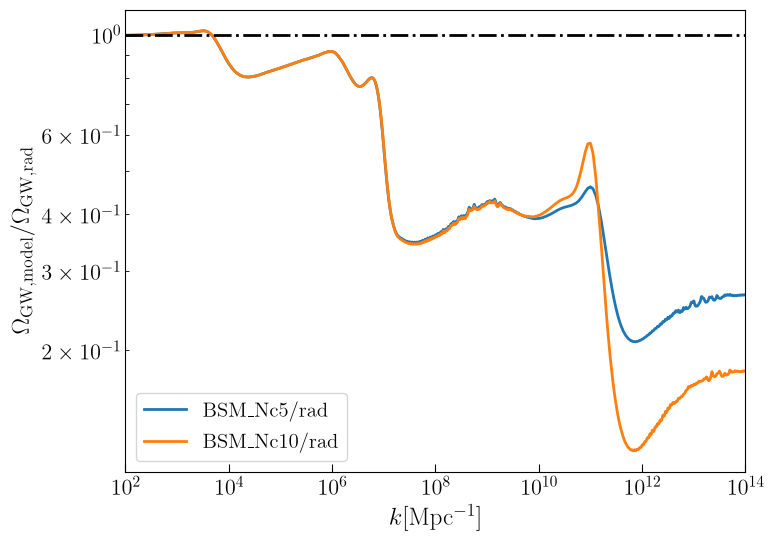

In [23]:
fig, ax = plt.subplots(figsize=(8, 6))
standard_flat = 3.45334986e-05
data = np.loadtxt('data/flat_BSM_nc5.csv', delimiter=",", skiprows=1)
kspan = data[:,0]
OmegaGW =data[:,1]
plt.plot(kspan,OmegaGW/standard_flat,label='BSM_Nc5/rad')
data = np.loadtxt(DATA_DIR / f'flat_BSM_nc10.csv', delimiter=",", skiprows=1)
kspan = data[:,0]
OmegaGW =data[:,1]
plt.plot(kspan,OmegaGW/standard_flat,label='BSM_Nc10/rad')
plt.xlabel(r'$k [\rm Mpc^{-1}]$')
plt.ylabel(r'$\Omega_{\mathrm{GW,model}}/\Omega_{\mathrm{GW,rad}}$')
plt.axhline(1,ls='-.',color='black')
plt.xlim(1e+2,1e+14)
plt.xscale('log')
plt.yscale('log')
#plt.loglog(k_eval, today_redshift_factor(1/k_eval,1e-4)/today_redshift_factor(1e-3,1e-4),ls='-.',label=r'entropy dilution factor')
plt.legend()
plt.show()


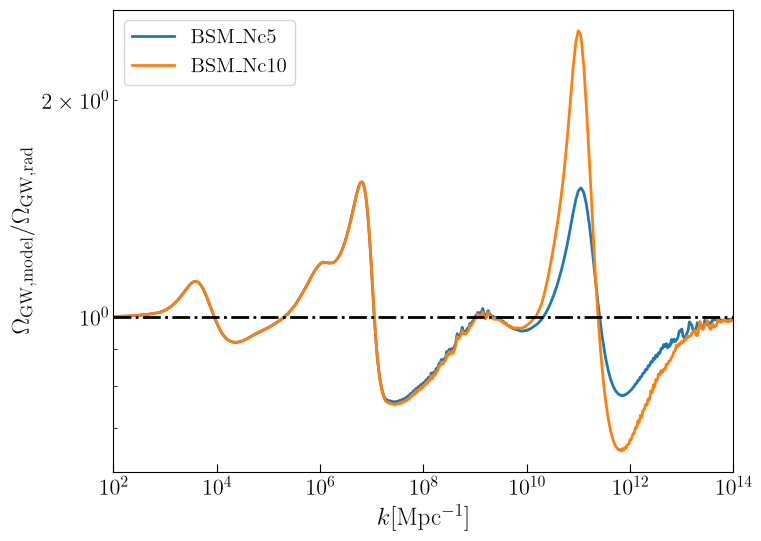

In [22]:
fig, ax = plt.subplots(figsize=(8, 6))
data = np.loadtxt('data/flat_BSM_nc5_early.csv', delimiter=",", skiprows=1)
kspan = data[:,0]
OmegaGW =data[:,1]
plt.plot(kspan,OmegaGW/OmegaGW[0],label='BSM_Nc5')
data = np.loadtxt(DATA_DIR / f'flat_BSM_nc10_early.csv', delimiter=",", skiprows=1)
kspan = data[:,0]
OmegaGW =data[:,1]
plt.plot(kspan,OmegaGW/OmegaGW[0],label='BSM_Nc10')
plt.xlabel(r'$k [\rm Mpc^{-1}]$')
plt.ylabel(r'$\Omega_{\mathrm{GW,model}}/\Omega_{\mathrm{GW,rad}}$')
plt.axhline(1,ls='-.',color='black')
plt.xlim(1e+2,1e+14)
plt.xscale('log')
plt.yscale('log')
#plt.loglog(k_eval, today_redshift_factor(1/k_eval,1e-4)/today_redshift_factor(1e-3,1e-4),ls='-.',label=r'entropy dilution factor')
plt.legend()
plt.show()


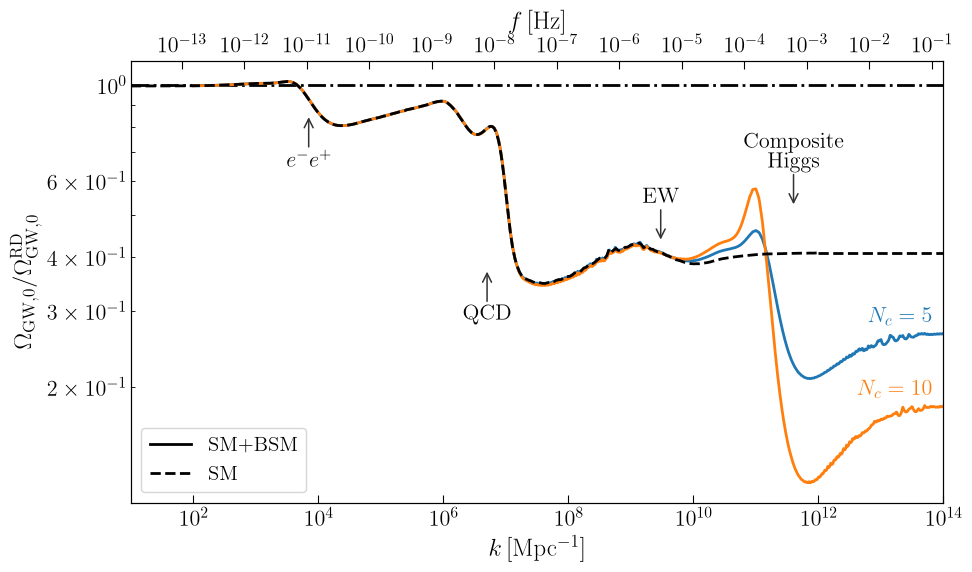

In [25]:
standard_flat = 3.45334986e-05
from matplotlib.lines import Line2D
fig, ax = plt.subplots(figsize=(10, 6))
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel(r'$k\,[\rm Mpc^{-1}]$')
ax.set_ylabel(r'$\Omega_{\mathrm{GW,0}}/\Omega_{\mathrm{GW,0}}^{\rm RD}$')
ax.axhline(1, ls='-.', color='black')
ax.set_xlim(1e1, 1e14)

data = np.loadtxt('data/flat_BSM_nc5.csv', delimiter=",", skiprows=1)
kspan = data[:, 0]
OmegaGW = data[:, 1]
nc5_line, = ax.plot(kspan, OmegaGW / standard_flat)
ax.annotate(r'$N_c=5$', xy=(kspan[-1], OmegaGW[-1] / standard_flat),
            xytext=(-8, 5), textcoords='offset points',
            ha='right', va='bottom', color=nc5_line.get_color())

data = np.loadtxt(DATA_DIR / f'flat_BSM_nc10.csv', delimiter=",", skiprows=1)
kspan = data[:, 0]
OmegaGW = data[:, 1]
nc10_line, = ax.plot(kspan, OmegaGW / standard_flat)
ax.annotate(r'$N_c=10$', xy=(kspan[-1], OmegaGW[-1] / standard_flat),
            xytext=(-8, 5), textcoords='offset points',
            ha='right', va='bottom', color=nc10_line.get_color())

data = np.loadtxt('data/flat_QCD_new.csv', delimiter=",", skiprows=1)
kspan = data[:, 0]
OmegaGW = data[:, 1]
sm_line, = ax.plot(kspan, OmegaGW / standard_flat, label='SM',color='black',ls='--')
ax.axhline(OmegaGW[-1] / standard_flat, xmin=11/13,xmax=1, color='black',ls='--')

# Upper horizontal axis: cyclic frequency today, f = k c / (2 pi).
# Use decade ticks and display them as 10^n.
ax_frequency = ax.twiny()
ax_frequency.set_xscale('log')
ax_frequency.set_xlim(ax.get_xlim())
f_min = k_mpc_to_hz(ax.get_xlim()[0])
f_max = k_mpc_to_hz(ax.get_xlim()[1])
f_exponents = np.arange(
    int(np.ceil(np.log10(f_min))),
    int(np.floor(np.log10(f_max))) + 1,
)
f_ticks = 10.0**f_exponents
k_ticks = hz_to_k_mpc(f_ticks)
ax_frequency.set_xticks(k_ticks)
ax_frequency.set_xticklabels([
    rf'$10^{{{exponent:d}}}$' for exponent in f_exponents
])
ax_frequency.set_xlabel(r'$f\,[\rm Hz]$')

# Independent label positions.  Change these y values manually as needed.
electron_text_y = 0.8
qcd_text_y = 0.45
ew_text_y = 0.67
bsm_text_y = 0.75
transition_x = {
    'e-e+': 7e3,
    'QCD': 5e6,
    'EW': 3e9,
    'composite Higgs': 4e11,
}
arrow_length = 0.08
arrow_style = dict(
    arrowstyle='->', color='0.2', lw=1.1,
    shrinkA=0, shrinkB=2,
)

# Keep the e-e+ and EW arrows vertical; point QCD and composite Higgs rightward.
ax.annotate(r'$e^-e^+$',
            xy=(transition_x['e-e+'], electron_text_y + arrow_length),
            xycoords=('data', 'axes fraction'),
            xytext=(transition_x['e-e+'], electron_text_y),
            textcoords=('data', 'axes fraction'),
            ha='center', va='top', arrowprops=arrow_style)
ax.annotate('EW',
            xy=(transition_x['EW'], ew_text_y - arrow_length),
            xycoords=('data', 'axes fraction'),
            xytext=(transition_x['EW'], ew_text_y),
            textcoords=('data', 'axes fraction'),
            ha='center', va='bottom', arrowprops=arrow_style)
ax.annotate('QCD',
            xy=(transition_x['QCD'], qcd_text_y+arrow_length),
            xycoords=('data', 'axes fraction'),
            xytext=(transition_x['QCD'], qcd_text_y),
            textcoords=('data', 'axes fraction'),
            ha='center', va='top', arrowprops=arrow_style)
ax.annotate('Composite\nHiggs',
            xy=(transition_x['composite Higgs'], bsm_text_y-arrow_length),
            xycoords=('data', 'axes fraction'),
            xytext=(transition_x['composite Higgs'] , bsm_text_y),
            textcoords=('data', 'axes fraction'),
            ha='center', va='bottom', multialignment='center', arrowprops=arrow_style)

ax.legend(handles=[Line2D([0], [0], color='black',
                          lw=nc5_line.get_linewidth(), label='SM+BSM'), sm_line])
fig.tight_layout()
plt.savefig('plot/flat_GWspectrum_BSM.pdf')
plt.show()
